# Avaliação do Modelo — In-Time vs. Out-of-Time (OOT)

Este caderno é a **prova final** do modelo campeão de detecção de fraude exportado pelo `02_Modelagem.ipynb` (`LGBM_Otimizado` + calibração isotônica + **threshold dinâmico por ticket**). Pela primeira vez o bloco **Out-of-Time** (`df_oot`, os 20% mais recentes) entra em cena: ele não participou de tuning, poda SHAP, calibração nem da escolha do threshold.

> **Pergunta central:** o modelo continua **discriminando**, **decidindo** e **gerando lucro** em um período futuro que nunca viu? Onde ele perde força?

### Roteiro (storytelling)

| Seção | Pergunta de negócio | Análises |
|:---:|---|---|
| **1.0** | O que vamos avaliar? | Artefato, split temporal e escoragem — **In-Time = Treino (OOF) + Validação** |
| **2.0** | Quão bom é o modelo fora do tempo? | GINI, ROC-AUC, KS, PR-AUC, regra de decisão, resultado financeiro e matriz de confusão |
| **3.0** | A capacidade de ordenar risco se manteve? | Curvas ROC e Precision-Recall In-Time × OOT |
| **4.0** | Fraudes e legítimas continuam separadas? | KDE dos scores, KS (CDF) e escada de risco por decil |
| **5.0** | O modelo decide pelos motivos certos? | SHAP global, direção do impacto e estabilidade dos motores de decisão |
| **6.0** | O que mudou no mundo? | Target drift, PSI do score e PSI das features × importância SHAP |
| **7.0** | A performance é estável semana a semana? | GINI por semana ao longo de Treino → Validação → OOT |
| **8.0** | Onde o modelo falha? | Recall e prejuízo vazado por arquétipo/cluster de fraude e raio-X das fraudes que passaram |
| **9.0** | Vai para produção? | Semáforo Go/No-Go e exportação das métricas de monitoramento |


---
## 1.0 Configuração, Carga do Artefato e Escoragem

- Imports, resolução da raiz do projeto (local ou Colab) e funções de `utils.py` — as funções de avaliação foram **portadas do caderno `04_Model_Avaliation` (Projeto_06)** e adaptadas para fraude, threshold dinâmico e a paleta azul corporativa (`aplicar_estilo_azul`).
- Flags de execução para controlar processamento pesado e salvamento de figuras.

In [1]:
# ==============================================================================
# 1.0 CONFIGURAÇÃO DO AMBIENTE E IMPORTS
# ==============================================================================
import os
import sys
import json
import hashlib
import warnings
import importlib
from datetime import datetime
from pathlib import Path

warnings.filterwarnings('ignore')

# Resolução robusta da raiz do projeto (Local e Colab) — mesmo padrão do 02_Modelagem
current_dir = Path(os.getcwd()).resolve()
if (current_dir / 'utils.py').exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / 'utils.py').exists():
    PROJECT_ROOT = current_dir.parent
elif (current_dir.parent.parent / 'utils.py').exists():
    PROJECT_ROOT = current_dir.parent.parent
else:
    PROJECT_ROOT = current_dir

os.chdir(PROJECT_ROOT)
for p in [str(PROJECT_ROOT), os.path.abspath('.'), os.path.abspath('..')]:
    if p not in sys.path:
        sys.path.append(p)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import ks_2samp

import utils
importlib.reload(utils)
from utils import (
    # Pipeline do 02_Modelagem (split temporal + regra de decisão)
    preparar_dados_modelagem,
    threshold_calibrado_para_bruto,
    # Estilo corporativo azul
    aplicar_estilo_azul,
    PALETA_AZUL,
    # 1. Escoragem
    gerar_scores_oof_treino,
    escorar_particao,
    adicionar_bloco_temporal,
    # 2-4. Performance, discriminação e separação
    tabela_metricas_janelas,
    formatar_tabela_metricas,
    plot_matrizes_confusao_janelas,
    plot_roc_pr_janelas,
    plot_kde_scores_janelas,
    plot_cdf_ks_janelas,
    gerar_tabela_decis_ks,
    plot_decis_janelas,
    # 5. SHAP
    calcular_shap_lgbm,
    ranking_shap,
    plot_importancia_shap,
    plot_shap_beeswarm,
    plot_shap_janelas,
    # 6-7. Drift e estabilidade temporal
    tabela_temporal,
    plot_target_drift_temporal,
    teste_qui_quadrado_temporal,
    calcular_psi_scores,
    plot_psi_score_faixas,
    relatorio_psi_features,
    plot_psi_vs_shap,
    plot_comparativo_psi_features,
    plot_gini_temporal,
    # 8. Modelo x Clusters
    obter_rotulos_clusters_fraude,
    avaliar_modelo_por_grupo,
    plot_recall_grupos_janelas,
    plot_score_fraudes_por_grupo,
    plot_matriz_prioridade_clusters,
    perfil_fn_vs_vp,
)

aplicar_estilo_azul()
pd.set_option('display.max_columns', 60)

# ------------------------------------------------------------------------------
# Flags e parâmetros da avaliação
# ------------------------------------------------------------------------------
USAR_OOF_TREINO = True      # True: Treino escorado Out-of-Fold (honesto) | False: in-sample (otimista, ~4x mais rápido)
N_AMOSTRA_SHAP  = 20_000    # amostra por janela para o TreeExplainer
DIAS_POR_BLOCO  = 7         # granularidade temporal (7 = semanal; 30 = mensal)
RANDOM_STATE    = 42

SALVAR_FIGURAS = False
DIR_FIGURAS = PROJECT_ROOT / 'reports' / 'figures' / '04_avaliacao'
DIR_METRICAS = PROJECT_ROOT / 'reports' / 'metrics'
DIR_METRICAS.mkdir(parents=True, exist_ok=True)

def fig_path(nome: str):
    # Caminho da figura quando SALVAR_FIGURAS = True (None = apenas exibe inline)
    return DIR_FIGURAS / nome if SALVAR_FIGURAS else None

print(f"Diretório raiz configurado: {PROJECT_ROOT}")
print("Funções de avaliação OOT importadas de utils.py | estilo azul corporativo aplicado.")

Diretório raiz configurado: /content
Funções de avaliação OOT importadas de utils.py | estilo azul corporativo aplicado.


### 1.1 Carga da Master Table e do Artefato Final

O artefato `modelo_fraude_final.joblib` (Seção 8.3 do `02_Modelagem`) contém tudo o que a inferência precisa: estimador treinado em 100% do Treino, calibrador isotônico, lista de features e os parâmetros da regra dinâmica:

$$\text{bloquear se } p_{cal} \geq t_{min} + (t_{max} - t_{min}) \cdot e^{-k \cdot \text{Valor US\$}}$$

In [2]:
# ==============================================================================
# 1.1 CARGA DA MASTER TABLE, METADADOS E ARTEFATO DO MODELO FINAL
# ==============================================================================
dir_dados = PROJECT_ROOT / 'data' / 'processed'
dir_artifacts = PROJECT_ROOT / 'artifacts'

caminhos = {
    'master':   dir_dados / 'df_master.parquet',
    'meta':     dir_dados / 'features_metadata.json',
    'artefato': dir_artifacts / 'modelo_fraude_final.joblib',
    'metadata': dir_artifacts / 'modelo_fraude_final_metadata.json',
    'metrics':  dir_artifacts / 'modelo_fraude_final_metrics.json',
}
faltantes = [k for k, c in caminhos.items() if not c.exists()]
if faltantes:
    raise FileNotFoundError(
        f"Arquivos não encontrados: {faltantes}. Execute 01_EDA.ipynb (df_master) e 02_Modelagem.ipynb (Seção 8.3) antes."
    )

df_master = pd.read_parquet(caminhos['master'])
with open(caminhos['meta'], 'r', encoding='utf-8') as f:
    meta = json.load(f)

artefato = joblib.load(caminhos['artefato'])
with open(caminhos['metadata'], 'r', encoding='utf-8') as f:
    modelo_metadata = json.load(f)
with open(caminhos['metrics'], 'r', encoding='utf-8') as f:
    modelo_metrics = json.load(f)

FEATURES = artefato['features']
REGRA = artefato['regra_decisao']
hash_artefato = hashlib.md5(caminhos['artefato'].read_bytes()).hexdigest()[:8]

print('=' * 78)
print(f" Master Table        : {df_master.shape[0]:,} transações x {df_master.shape[1]} colunas")
print(f" Modelo              : {artefato['nome_modelo']} ({modelo_metadata.get('classe', '-')}) | hash {hash_artefato}")
print(f" Features            : {len(FEATURES)}")
print(f" Calibração          : {modelo_metadata.get('calibracao', '-')}")
print(f" Regra de decisão    : bloquear se p_cal >= {REGRA['t_min']:.4f} + ({REGRA['t_max']:.4f} - {REGRA['t_min']:.4f})"
      f" · exp(-{REGRA['k']:.5f} · Valor US$)")
print(f" Threshold fixo ref. : {REGRA.get('threshold_fixo_referencia')}")
print('=' * 78)

 Master Table        : 590,540 transações x 156 colunas
 Modelo              : LGBM_Otimizado (lightgbm.sklearn.LGBMClassifier) | hash 1ea0f90e
 Features            : 44
 Calibração          : IsotonicRegression (ajustada no OOF do Treino)
 Regra de decisão    : bloquear se p_cal >= 0.0327 + (0.0502 - 0.0327) · exp(-0.02459 · Valor US$)
 Threshold fixo ref. : 0.03463580046895069


### 1.2 Reconstrução do Split Temporal e Definição das Janelas

O split é reconstruído com **a mesma função e proporções** do `02_Modelagem` (`preparar_dados_modelagem`, 60/20/20 por `TransactionDT`) — as agregações, frequency encodings e o ordinal encoding continuam ajustados **somente no Treino**, então o OOT recebe exatamente as transformações que receberia em produção.

| Janela | Composição | Papel |
|---|---|---|
| **In-Time** | Treino (60%) + Validação (20%) | Referência: o período que o modelo "conhece" |
| **Out-of-Time** | OOT (20% finais) | Teste cego: o futuro |

> **Cuidado metodológico — Treino Out-of-Fold:** o artefato foi treinado em 100% do Treino. Escorar o Treino com ele seria avaliar o modelo em dados que ele **memorizou** (no `02`, o GINI de treino in-sample chegou a ~0,97 contra ~0,81 na validação). Por isso, o Treino é escorado **Out-of-Fold** (`GroupKFold` mensal, mesmos hiperparâmetros e mesmos folds usados para ajustar o calibrador). Assim, as duas metades do In-Time são **fora da amostra** e a comparação com o OOT é justa.

In [3]:
# ==============================================================================
# 1.2 SPLIT TEMPORAL (MESMA ESTEIRA DO 02_MODELAGEM) — IN-TIME x OOT
# ==============================================================================
dados_prep = preparar_dados_modelagem(df_master=df_master, meta=meta, train_ratio=0.60, test_ratio=0.20)

X_train, y_train = dados_prep['X_train'], dados_prep['y_train']
X_val,   y_val   = dados_prep['X_test'],  dados_prep['y_test']
X_oot,   y_oot   = dados_prep['X_oot'],   dados_prep['y_oot']
train_df, df_validacao, oot_df = dados_prep['train_df'], dados_prep['test_df'], dados_prep['oot_df']
grupos_mes = dados_prep['grupos_mes']

# Sanidade: todas as features do artefato precisam existir após a engenharia pós-split
features_ausentes = [f for f in FEATURES if f not in X_oot.columns]
assert not features_ausentes, f"Features do artefato ausentes no OOT: {features_ausentes}"

# Matriz In-Time (Treino + Validação) com as features do modelo — usada em SHAP e PSI
X_in_time = pd.concat([X_train[FEATURES], X_val[FEATURES]])
X_oot_m = X_oot[FEATURES]

dia = lambda df: df['TransactionDT'] / 86400
print(f"\nPeríodo In-Time : dia {dia(train_df).min():.0f} → {dia(df_validacao).max():.0f}")
print(f"Período OOT     : dia {dia(oot_df).min():.0f} → {dia(oot_df).max():.0f}")

-----------------------------------------------------------------
X_train shape (60%): (354324, 154) | Taxa de Fraude: 3.38%
X_test  shape (20%): (118108, 154)  | Taxa de Fraude: 3.90%
X_oot   shape (20%): (118108, 154)  | Taxa de Fraude: 3.44%  [BLINDADO P/ AVALIAÇÃO FINAL]
Total de features preditoras: 154
Features lineares (LR): 47
Taxa de desbalanceamento (Treino): 28.56:1
Blocos mensais no Treino (GroupKFold): [0, 1, 2, 3] (Total: 4 meses)
-----------------------------------------------------------------

Período In-Time : dia 1 → 141
Período OOT     : dia 141 → 183


### 1.3 Score das Partições

Cada transação recebe: probabilidade **bruta** (usada nas métricas de ranqueamento, como no `02`), probabilidade **calibrada**, o **corte dinâmico** do seu ticket e a **decisão** (bloquear/aprovar). Também é criado o bloco temporal (`semana`) para as análises de estabilidade.

In [4]:
# ==============================================================================
# 1.3 SCORE: TREINO (OOF) + VALIDAÇÃO + OOT COM O ARTEFATO CONGELADO
# ==============================================================================
if USAR_OOF_TREINO:
    print("[INFO] Gerando scores Out-of-Fold do Treino (GroupKFold mensal, hiperparâmetros do artefato)...")
    prob_raw_treino = gerar_scores_oof_treino(artefato, X_train, y_train, groups=grupos_mes, n_splits=4)
    rotulo_treino = 'Treino (OOF)'
else:
    print("[AVISO] USAR_OOF_TREINO = False → Treino escorado in-sample: métricas In-Time ficarão OTIMISTAS.")
    prob_raw_treino = None
    rotulo_treino = 'Treino (OOF)'  # rótulo mantido para os gráficos; interprete como in-sample

df_scores = pd.concat([
    escorar_particao(artefato, X_train, train_df, rotulo_treino, 'In-Time', prob_raw=prob_raw_treino),
    escorar_particao(artefato, X_val, df_validacao, 'Validação', 'In-Time'),
    escorar_particao(artefato, X_oot, oot_df, 'OOT', 'OOT'),
])
df_scores = adicionar_bloco_temporal(df_scores, dt_inicio=df_master['TransactionDT'].min(),
                                     dias_por_bloco=DIAS_POR_BLOCO, nome_coluna='semana')

base_treino = df_scores[df_scores['Particao'] == rotulo_treino]
base_val    = df_scores[df_scores['Particao'] == 'Validação']
base_it     = df_scores[df_scores['Janela'] == 'In-Time']
base_oot    = df_scores[df_scores['Janela'] == 'OOT']

# Faixa do corte dinâmico convertida para a escala da probabilidade BRUTA (usada nos gráficos de score)
FAIXA_CORTE_RAW = (
    threshold_calibrado_para_bruto(artefato['calibrador'], REGRA['t_min']),
    threshold_calibrado_para_bruto(artefato['calibrador'], REGRA['t_max']),
)

resumo = df_scores.groupby('Particao', sort=False).agg(
    Transacoes=('isFraud', 'size'),
    Taxa_Fraude=('isFraud', 'mean'),
    Prob_Calibrada_Media=('prob_cal', 'mean'),
    Ticket_Medio_USD=('amt_usd', 'mean'),
    Pct_Bloqueado=('bloquear', 'mean'),
)
resumo['Erro_Calibracao_Rel'] = resumo['Prob_Calibrada_Media'] / resumo['Taxa_Fraude'] - 1
display(resumo.style.format({
    'Transacoes': '{:,.0f}', 'Taxa_Fraude': '{:.2%}', 'Prob_Calibrada_Media': '{:.2%}',
    'Ticket_Medio_USD': '$ {:,.2f}', 'Pct_Bloqueado': '{:.2%}', 'Erro_Calibracao_Rel': '{:+.1%}',
}).set_properties(subset=pd.IndexSlice[['OOT'], :], **{'background-color': PALETA_AZUL['gelo'], 'color': '#000000', 'font-weight': 'bold'}))
print(f"Faixa do corte dinâmico na escala bruta: [{FAIXA_CORTE_RAW[0]:.4f} (alto ticket) – {FAIXA_CORTE_RAW[1]:.4f} (micro-compra)]")

[INFO] Gerando scores Out-of-Fold do Treino (GroupKFold mensal, hiperparâmetros do artefato)...
  [OOF] fold 1/4 concluído | 130,968 transações escoradas
  [OOF] fold 2/4 concluído | 91,768 transações escoradas
  [OOF] fold 3/4 concluído | 89,838 transações escoradas
  [OOF] fold 4/4 concluído | 41,750 transações escoradas


,Transacoes,Taxa_Fraude,Prob_Calibrada_Media,Ticket_Medio_USD,Pct_Bloqueado,Erro_Calibracao_Rel
Particao,,,,,,
Treino (OOF),"354,324",3.38%,3.38%,$ 134.32,16.40%,+0.0%
Validação,"118,108",3.90%,3.14%,$ 134.63,14.55%,-19.7%
OOT,"118,108",3.44%,2.95%,$ 137.53,14.17%,-14.4%


Faixa do corte dinâmico na escala bruta: [0.4569 (alto ticket) – 0.5538 (micro-compra)]


> **Como ler:**
> - **`Taxa_Fraude`** por partição já antecipa o *target drift* (Seção 6.1).
> - **`Erro_Calibracao_Rel`** compara a probabilidade calibrada média com a taxa real: perto de 0% = calibração preservada. Um erro grande no OOT significa que o **corte dinâmico** (definido em probabilidade calibrada) passa a bloquear mais/menos do que o planejado, mesmo que o ranqueamento continue bom.
> - **`Pct_Bloqueado`** é o volume operacional da regra: variações fortes no OOT impactam o time de análise e o atrito com clientes.
>
> **Análise de Resultados** — 📝 _preencher após a execução_

---
## 2.0 Performance Global — Treino (OOF) · Validação · In-Time · OOT

Métricas organizadas em três blocos, todas calculadas **uma única vez** por base com o artefato congelado:

| Bloco | Métricas | O que respondem |
|---|---|---|
| **Ranqueamento** (prob. bruta) | ROC-AUC, **GINI** = 2·AUC − 1, **KS**, PR-AUC | O modelo ordena fraude acima de legítima? (independe do corte) |
| **Regra de decisão** (threshold dinâmico) | Precision, Recall, F1, Aprovação, Aceitação | O corte de produção continua bem calibrado? |
| **Financeiro** (US$) | Chargeback FN, Lucro Líquido, Lucro/Transação, Margem | O modelo continua gerando valor? |

A coluna **Δ (OOT − In-Time)** é o termômetro da generalização temporal. Métricas de volume (contagens e US$ totais) não têm Δ, pois as bases têm tamanhos diferentes — compare **Lucro por Transação** e **Margem s/ Volume**.

In [5]:
# ==============================================================================
# 2.0 RELATÓRIO DE MÉTRICAS POR JANELA (SEM CROSS-VALIDATION)
# ==============================================================================
bases_avaliacao = {
    rotulo_treino: base_treino,
    'Validação':   base_val,
    'In-Time':     base_it,
    'OOT':         base_oot,
}
df_metricas = tabela_metricas_janelas(bases_avaliacao, ref='In-Time', alvo='OOT')
display(formatar_tabela_metricas(df_metricas, destacar='OOT'))

df_metricas.to_csv(DIR_METRICAS / 'avaliacao_metricas_in_time_vs_oot.csv')
m_it, m_oot = df_metricas['In-Time'], df_metricas['OOT']
print(f"[RESUMO] GINI: {m_it['GINI']:.4f} → {m_oot['GINI']:.4f} ({(m_oot['GINI'] / m_it['GINI'] - 1) * 100:+.1f}%) | "
      f"KS: {m_it['KS']:.4f} → {m_oot['KS']:.4f} | Recall: {m_it['Recall']:.1%} → {m_oot['Recall']:.1%} | "
      f"Lucro/tx: $ {m_it['Lucro por Transação']:.3f} → $ {m_oot['Lucro por Transação']:.3f}")

,Treino (OOF),Validação,In-Time,OOT,Δ (OOT − In-Time)
Métrica,,,,,
Transações,"354,324","118,108","472,432","118,108",—
Taxa de Fraude,3.38%,3.90%,3.51%,3.44%,-0.07 p.p.
ROC-AUC,0.8907,0.9082,0.8952,0.8803,-0.0149
GINI,0.7814,0.8165,0.7905,0.7607,-0.0298
KS,0.6214,0.6545,0.6278,0.5960,-0.0318
PR-AUC,0.4259,0.5164,0.4477,0.4254,-0.0223
Precision,15.77%,20.47%,16.85%,17.07%,+0.22 p.p.
Recall,76.45%,76.30%,76.41%,70.30%,-6.11 p.p.
F1-Score,0.2615,0.3229,0.2760,0.2747,-0.0013


[RESUMO] GINI: 0.7905 → 0.7607 (-3.8%) | KS: 0.6278 → 0.5960 | Recall: 76.4% → 70.3% | Lucro/tx: $ 0.570 → $ 0.292


### 2.1 Matriz de Confusão — In-Time vs. OOT

Decisão final do threshold dinâmico. Percentuais **sobre a classe real** (cada linha soma 100%):
- **VN** — legítima aprovada (receita +2%) · **FP** — legítima bloqueada (atrito e −2%)
- **FN** — fraude aprovada (chargeback −100%) · **VP** — fraude barrada (prejuízo evitado)

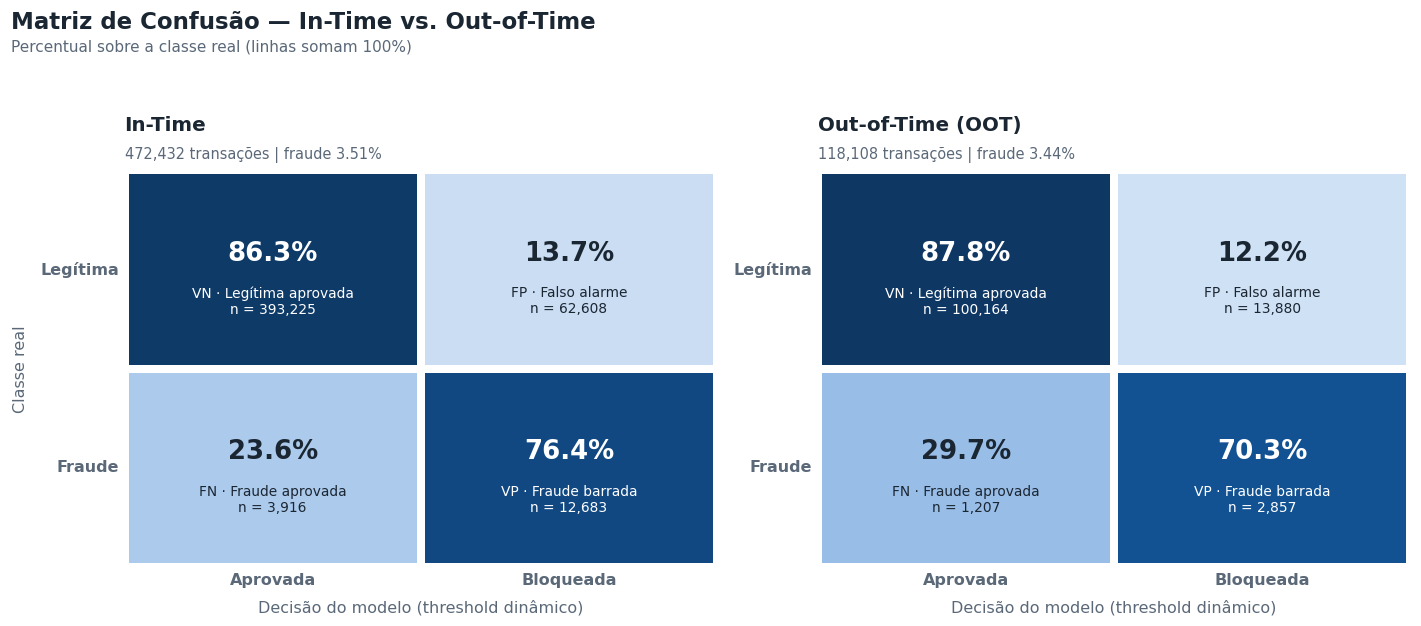

In [6]:
# ==============================================================================
# 2.1 MATRIZES DE CONFUSÃO LADO A LADO (REGRA DINÂMICA)
# ==============================================================================
df_cm = plot_matrizes_confusao_janelas({'In-Time': base_it, 'Out-of-Time (OOT)': base_oot},
                                       filepath=fig_path('01_matriz_confusao_in_time_vs_oot.png'))
display(df_cm.style.format({'Transações': '{:,.0f}', '% da Classe': '{:.2%}'}))

> **Como ler:** o quadrante crítico em fraude é o **FN** (fraude aprovada = perda de 100% do valor). Se o % de FN sobe no OOT enquanto o GINI se mantém, o problema está no **corte/calibração**, não na capacidade de ordenação.
>
> **Análise de Resultados — Performance Global** — 📝 _preencher após a execução_
> - **Ranqueamento:** GINI/KS do OOT vs. In-Time (Δ absoluto e relativo).
> - **Regra de decisão:** variação de Recall e Precision; impacto no volume de FP.
> - **Financeiro:** Lucro por Transação e Margem no OOT vs. In-Time; lucro vs. cenário sem modelo.

---
## 3.0 Estabilidade da Discriminação — Curvas ROC e Precision-Recall

Sobrepor as curvas das duas janelas é a forma mais direta de verificar estabilidade: **curvas coladas = mesma capacidade de ordenação**. Em fraude (classe rara, ~3,5%), a curva **Precision-Recall** complementa a ROC — ela é sensível à prevalência e mostra o custo, em falsos alarmes, de cada ponto de recall.

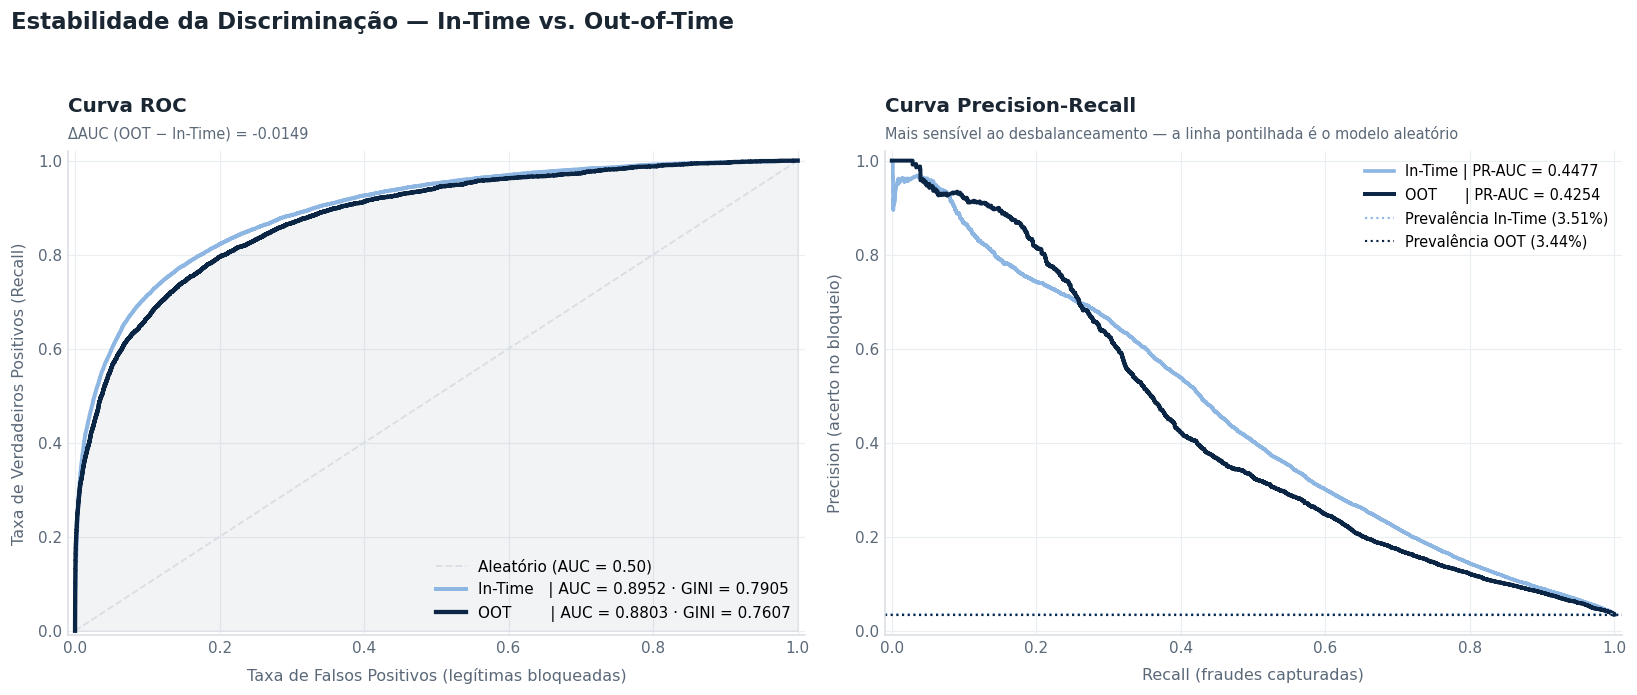

In [7]:
# ==============================================================================
# 3.0 CURVAS ROC E PR — IN-TIME x OOT
# ==============================================================================
aucs = plot_roc_pr_janelas(
    base_it['isFraud'], base_it['prob_raw'],
    base_oot['isFraud'], base_oot['prob_raw'],
    filepath=fig_path('02_roc_pr_in_time_vs_oot.png'),
)

> **Como ler:** a região mais relevante da ROC para fraude é o **início do eixo X** (baixa taxa de falsos positivos): é ali que o threshold de produção opera. Se as curvas se afastam apenas no meio/fim, o impacto operacional é pequeno.
>
> **Análise de Resultados — ROC/PR** — 📝 _preencher após a execução_

---
## 4.0 Separação de Risco — KDE, KS e Escada de Decis

Três lentes complementares sobre a mesma pergunta — *as distribuições de score de fraudes e legítimas continuam separadas?*
1. **KDE:** forma das distribuições por classe e posição da **faixa do corte dinâmico** (o corte varia com o ticket, por isso é uma faixa: à esquerda vale para alto ticket, à direita para micro-compras);
2. **KS (CDF):** distância máxima entre as distribuições acumuladas;
3. **Decis:** monotonicidade da taxa de fraude e captura acumulada (curva de ganho).

### Nota — Escala bruta × calibrada: por que o corte aparece em ~0,46–0,55 se a regra fala em 3–5%?

Os gráficos desta seção usam a **probabilidade bruta** do LightGBM, e não a calibrada. As duas escalas medem o mesmo risco, mas com réguas diferentes:

| Escala | De onde vem | Faixa do corte dinâmico | Para que serve |
|---|---|---|---|
| **Calibrada** ($p_{cal}$) | saída da isotônica, ajustada no OOF do Treino | $t_{min}$ ≈ **3,3%** (alto ticket) – $t_{max}$ ≈ **5,0%** (micro-compra) | é a regra de decisão: "probabilidade real de fraude" |
| **Bruta** ($p_{raw}$) | `predict_proba` do LightGBM | ≈ **0,457 – 0,554** | ranqueamento (AUC, KS, GINI, KDE, decis) |

**Por que a bruta fica tão "inflada"?** O modelo foi treinado com `scale_pos_weight` ≈ n_legítimas / n_fraudes ≈ **28** (fraude ≈ 3,4%). Esse peso multiplica as *odds* de fraude que o modelo aprende por ~28, de modo que

$$\frac{p_{raw}}{1-p_{raw}} \approx 28 \cdot \frac{p_{real}}{1-p_{real}} \quad\Rightarrow\quad p_{real}=3{,}3\% \;\to\; \text{odds } 0{,}034 \times 28 \approx 0{,}96 \;\to\; p_{raw}\approx 0{,}49$$

Ou seja, um score bruto perto de 0,5 corresponde, na prática, a ~3–5% de chance real de fraude. A **calibração isotônica** desfaz essa distorção: é uma função **monotônica** (nunca inverte a ordem), então o corte $p_{cal} \geq t$ equivale exatamente a $p_{raw} \geq t_{raw}$. A conversão é feita por `threshold_calibrado_para_bruto` (Seção 1.3), e a relação não é exatamente a fórmula acima porque a isotônica é estimada empiricamente nos dados.

**Por que não plotar direto na calibrada?** A isotônica é uma função em degraus: ela comprime quase toda a massa em poucos valores perto de 0, o que deixaria o KDE ilegível. AUC, KS e GINI **não mudam** entre as duas escalas, porque só dependem da ordem.

> **Leitura do gráfico:** o eixo **inferior** é o score bruto; o eixo **superior** mostra a probabilidade calibrada equivalente em cada posição. O rótulo em destaque (*corte 3,3%–5,0%*) fica exatamente sobre a faixa sombreada, ligando as duas escalas.


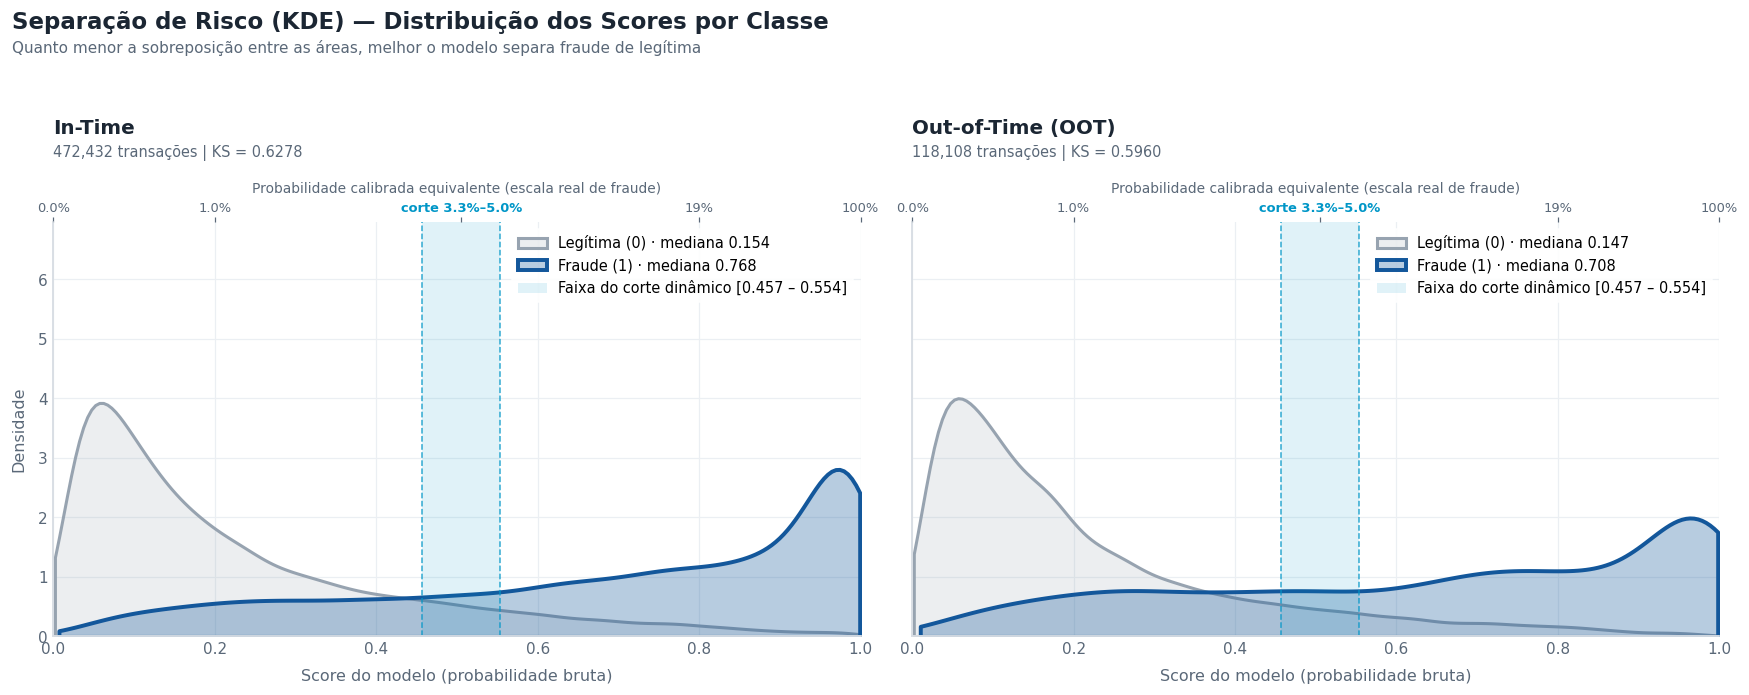

In [8]:
# ==============================================================================
# 4.1 SEPARAÇÃO DE RISCO (KDE) — IN-TIME x OOT
# ==============================================================================
plot_kde_scores_janelas(
    base_it['isFraud'], base_it['prob_raw'],
    base_oot['isFraud'], base_oot['prob_raw'],
    faixa_corte=FAIXA_CORTE_RAW,
    calibrador=artefato['calibrador'],   # eixo superior: probabilidade calibrada equivalente
    filepath=fig_path('03_kde_scores_in_time_vs_oot.png'),
)

> **Como ler:** a massa de **legítimas** deve se concentrar à esquerda da faixa de corte e a de **fraudes** à direita. A área de fraude que fica à esquerda da faixa é o **FN** (chargeback); a área de legítimas à direita é o **FP**. Compare o deslocamento das curvas entre os dois painéis: se a curva de fraude "escorrega" para a esquerda no OOT, os fraudadores ficaram mais parecidos com clientes legítimos.
>
> **Análise de Resultados — KDE** — 📝 _preencher após a execução_

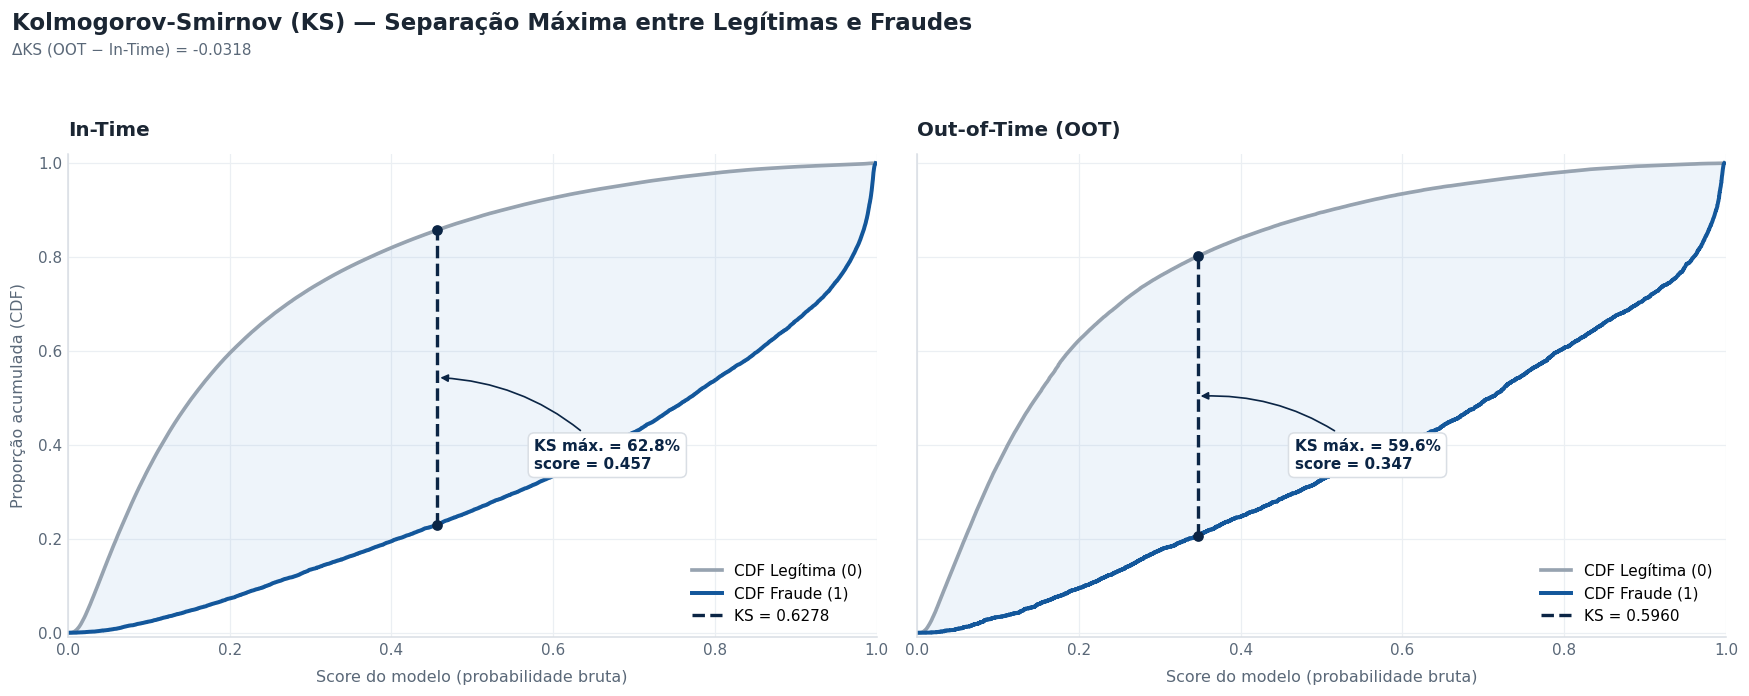

[KS] In-Time: 0.6278 | OOT: 0.5960 | Δ = -0.0318 (-5.1%)


In [9]:
# ==============================================================================
# 4.2 KOLMOGOROV-SMIRNOV (CDF) — IN-TIME x OOT
# ==============================================================================
ks_it, ks_oot = plot_cdf_ks_janelas(
    base_it['isFraud'], base_it['prob_raw'],
    base_oot['isFraud'], base_oot['prob_raw'],
    filepath=fig_path('04_cdf_ks_in_time_vs_oot.png'),
)
print(f"[KS] In-Time: {ks_it:.4f} | OOT: {ks_oot:.4f} | Δ = {ks_oot - ks_it:+.4f} ({(ks_oot / ks_it - 1) * 100:+.1f}%)")

> **Referência de mercado para KS:** < 0,20 fraco · 0,20–0,40 aceitável · 0,40–0,60 bom · > 0,60 excelente. Além do valor, observe se o **score do ponto de KS máximo** se desloca entre as janelas — isso indica se o "ponto de maior separação" continua próximo da faixa de corte.
>
> **Análise de Resultados — KS** — 📝 _preencher após a execução_

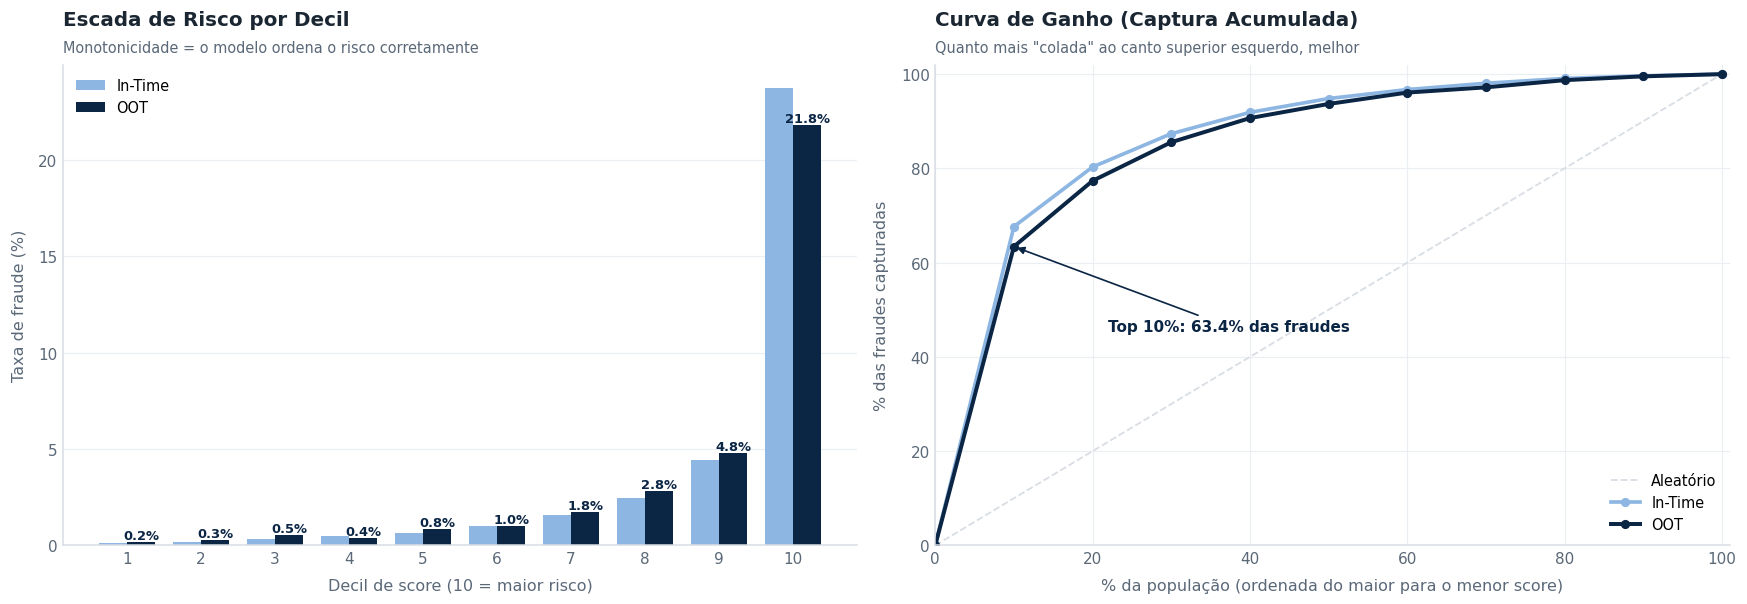

[OOT] Escada de risco monotônica: NÃO (há inversões) | Decil 10: taxa de fraude 21.82% · lift 6.3x · captura 63.4% das fraudes


Decil,Transações,Fraudes,Taxa Fraude (%),Score Mín,Score Máx,Captura Acum. (%),KS Acum. (%),Lift
10,"11,811","2,577",21.82%,0.5560,0.9979,63.4%,55.3%,6.34x
9,"11,811",567,4.80%,0.3709,0.5560,77.4%,59.4%,1.40x
8,"11,811",333,2.82%,0.2647,0.3709,85.6%,57.5%,0.82x
7,"11,810",208,1.76%,0.1973,0.2647,90.7%,52.5%,0.51x
6,"11,811",122,1.03%,0.1533,0.1973,93.7%,45.2%,0.30x
5,"11,811",98,0.83%,0.1160,0.1533,96.1%,37.4%,0.24x
4,"11,810",45,0.38%,0.0862,0.1160,97.2%,28.2%,0.11x
3,"11,811",62,0.52%,0.0606,0.0862,98.7%,19.4%,0.15x
2,"11,811",33,0.28%,0.0362,0.0606,99.5%,9.9%,0.08x
1,"11,811",19,0.16%,0.0020,0.0362,100.0%,0.0%,0.05x


In [10]:
# ==============================================================================
# 4.3 ESCADA DE RISCO POR DECIL E CURVA DE GANHO — IN-TIME x OOT
# ==============================================================================
tab_decis_it = gerar_tabela_decis_ks(base_it['isFraud'], base_it['prob_raw'], n_decis=10)
tab_decis_oot = gerar_tabela_decis_ks(base_oot['isFraud'], base_oot['prob_raw'], n_decis=10)

plot_decis_janelas(tab_decis_it, tab_decis_oot, filepath=fig_path('05_decis_ganho_in_time_vs_oot.png'))

monotonico_oot = bool(np.all(np.diff(tab_decis_oot['taxa_fraude_pct']) >= 0))
top = tab_decis_oot.loc[tab_decis_oot['decil'] == 10].iloc[0]
print(f"[OOT] Escada de risco monotônica: {'SIM' if monotonico_oot else 'NÃO (há inversões)'} | "
      f"Decil 10: taxa de fraude {top['taxa_fraude_pct']:.2f}% · lift {top['lift']:.1f}x · "
      f"captura {top['captura_fraudes_acum_pct']:.1f}% das fraudes")

display(tab_decis_oot[['decil', 'transacoes', 'fraudes', 'taxa_fraude_pct', 'score_min', 'score_max',
                       'captura_fraudes_acum_pct', 'ks_pct', 'lift']]
        .sort_values('decil', ascending=False)
        .rename(columns={'decil': 'Decil', 'transacoes': 'Transações', 'fraudes': 'Fraudes',
                         'taxa_fraude_pct': 'Taxa Fraude (%)', 'score_min': 'Score Mín', 'score_max': 'Score Máx',
                         'captura_fraudes_acum_pct': 'Captura Acum. (%)', 'ks_pct': 'KS Acum. (%)', 'lift': 'Lift'})
        .style.format({'Transações': '{:,.0f}', 'Fraudes': '{:,.0f}', 'Taxa Fraude (%)': '{:.2f}%',
                       'Score Mín': '{:.4f}', 'Score Máx': '{:.4f}', 'Captura Acum. (%)': '{:.1f}%',
                       'KS Acum. (%)': '{:.1f}%', 'Lift': '{:.2f}x'})
        .bar(subset=['Taxa Fraude (%)'], color=PALETA_AZUL['claro'], vmin=0)
        .hide(axis='index'))

> **Como ler:** a escada precisa ser **monotonicamente crescente** do decil 1 ao 10 — inversões indicam que o modelo perdeu a ordenação em alguma faixa. Na curva de ganho, o ponto *Top 10%* mostra quanto das fraudes está concentrado nos 10% de transações mais arriscadas: é o argumento operacional mais forte para uma fila de revisão manual.
>
> **Análise de Resultados — Ordenação de Risco** — 📝 _preencher após a execução_

---
## 5.0 Interpretabilidade — SHAP

Depois de medir **quanto** o modelo acerta, verificamos **por que** ele decide. Os valores SHAP (`TreeExplainer`, em log-odds) medem a contribuição marginal de cada variável:
1. **Importância global no OOT:** quais variáveis movem a decisão no período futuro (Top 3 em destaque);
2. **Beeswarm:** a **direção** do impacto — valores altos (azul marinho) empurram para fraude ou para legítima?
3. **Estabilidade dos motores:** o ranking de importância In-Time × OOT continua o mesmo? Mudanças fortes indicam que o modelo passou a decidir por motivos diferentes.

[INFO] Calculando SHAP values (20,000 transações por janela)...


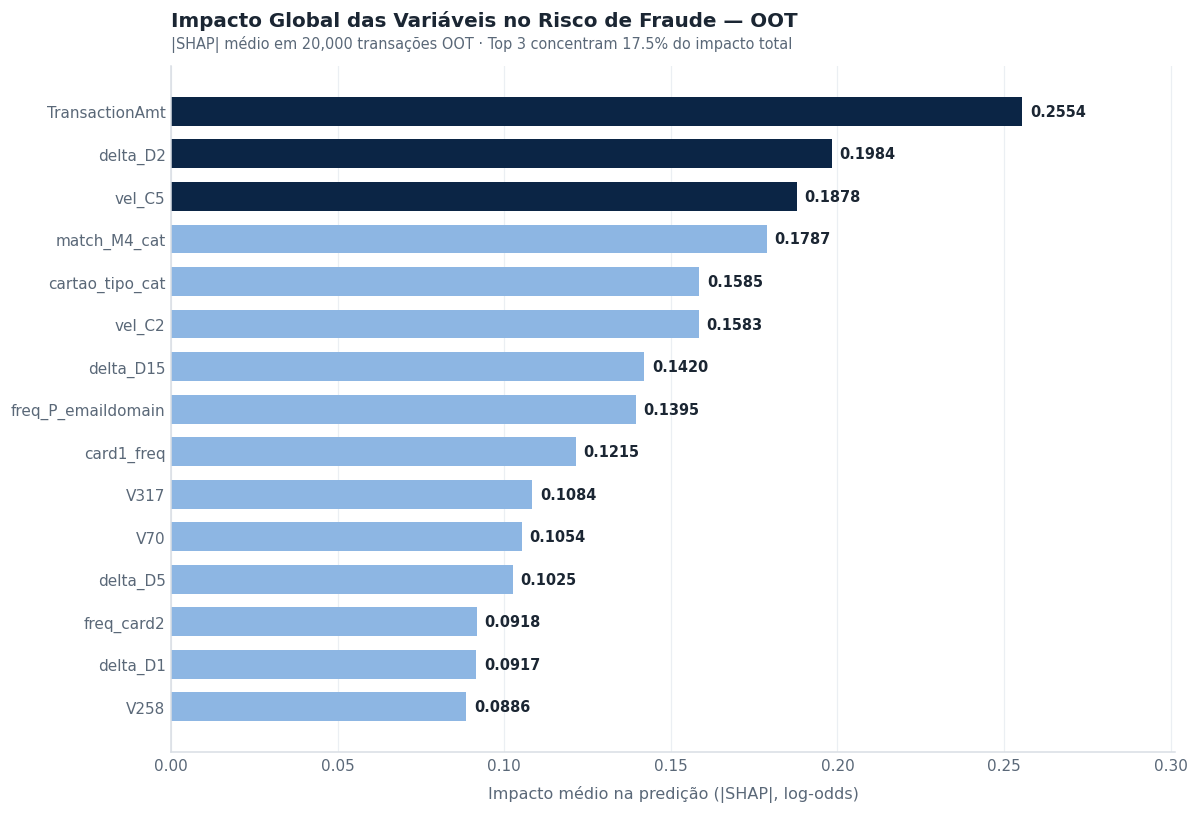

,Feature,SHAP_medio_abs,Rank,%_Impacto
0,TransactionAmt,0.255426,1,6.983233
1,delta_D2,0.198369,2,5.423327
2,vel_C5,0.187768,3,5.133503
3,match_M4_cat,0.178748,4,4.886885
4,cartao_tipo_cat,0.158494,5,4.333161
5,vel_C2,0.158316,6,4.328289
6,delta_D15,0.142000,7,3.882225
7,freq_P_emaildomain,0.139469,8,3.813020
8,card1_freq,0.121535,9,3.322724
9,V317,0.108421,10,2.964192


In [11]:
# ==============================================================================
# 5.1 SHAP VALUES (TREEEXPLAINER) — AMOSTRAS IN-TIME E OOT
# ==============================================================================
print(f"[INFO] Calculando SHAP values ({N_AMOSTRA_SHAP:,} transações por janela)...")
shap_oot, X_shap_oot = calcular_shap_lgbm(artefato['modelo'], X_oot_m, n_amostra=N_AMOSTRA_SHAP, random_state=RANDOM_STATE)
shap_it, X_shap_it = calcular_shap_lgbm(artefato['modelo'], X_in_time, n_amostra=N_AMOSTRA_SHAP, random_state=RANDOM_STATE)

rank_shap_oot = ranking_shap(shap_oot, FEATURES)
rank_shap_it = ranking_shap(shap_it, FEATURES)

plot_importancia_shap(
    rank_shap_oot, top_n=15, n_destaque=3,
    titulo='Impacto Global das Variáveis no Risco de Fraude — OOT',
    subtitulo=f"|SHAP| médio em {len(X_shap_oot):,} transações OOT · Top 3 concentram "
              f"{rank_shap_oot['%_Impacto'].head(3).sum():.1f}% do impacto total",
    filepath=fig_path('06_shap_importancia_oot.png'),
)

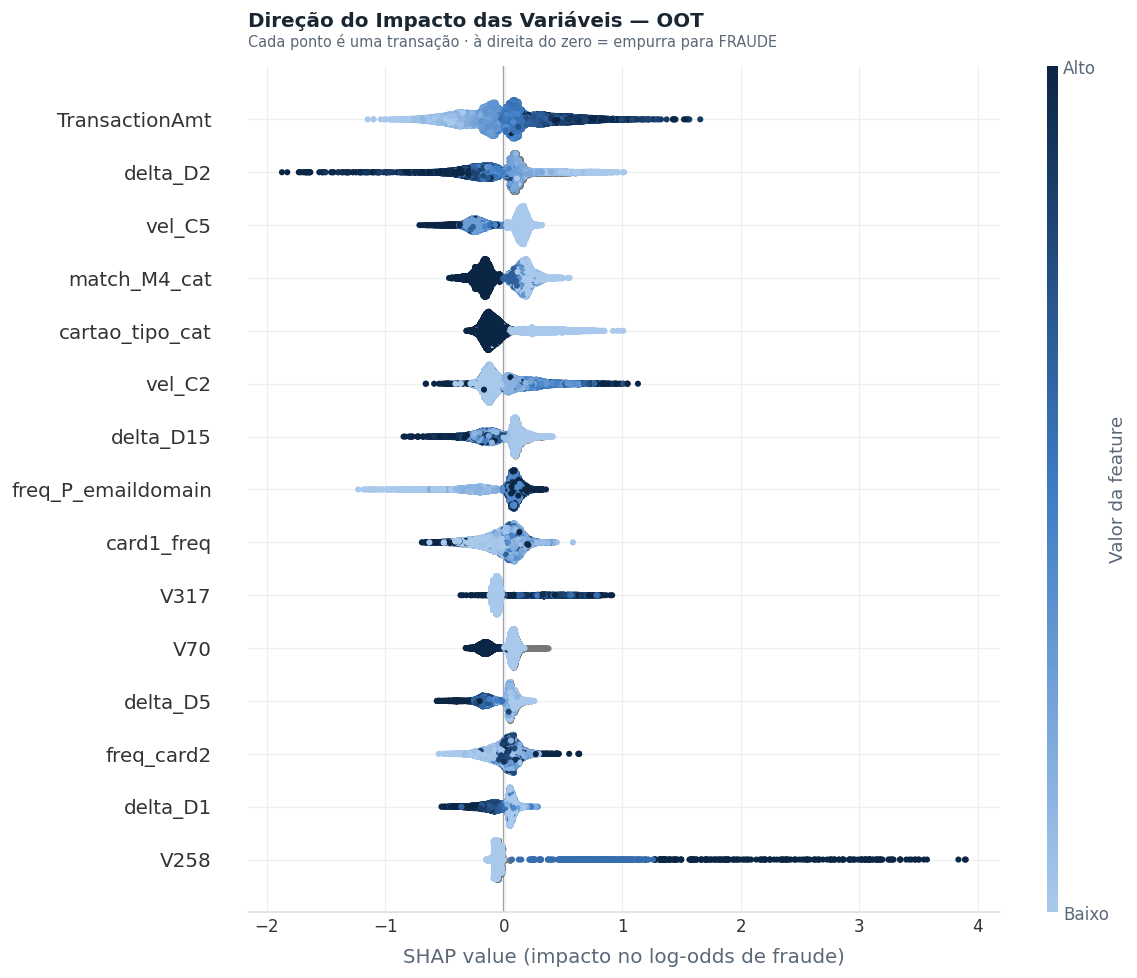

In [12]:
# ==============================================================================
# 5.2 DIREÇÃO DO IMPACTO (BEESWARM) — OOT
# ==============================================================================
plot_shap_beeswarm(shap_oot, X_shap_oot, top_n=15,
                   titulo='Direção do Impacto das Variáveis — OOT',
                   filepath=fig_path('07_shap_beeswarm_oot.png'))

---
## 6.0 Drift — O Que Mudou Entre In-Time e OOT?

Um modelo pode perder performance por três caminhos: **(i)** a taxa do evento muda (*target drift*), **(ii)** a população de entrada muda (*data drift*, medido pelo **PSI**) ou **(iii)** a relação entre features e fraude muda (*concept drift*, percebido pela queda do GINI na Seção 7.0).

| Faixa de PSI | Diagnóstico | Ação recomendada |
|:---:|:---:|---|
| PSI < 0,10 | Estável | Nenhuma intervenção |
| 0,10 ≤ PSI < 0,25 | Alerta (drift moderado) | Monitoramento intensificado |
| PSI ≥ 0,25 | Crítico (drift severo) | Investigar causa; avaliar re-treino/recalibração |

### 6.1 Target Drift — Taxa de Fraude ao Longo do Tempo

Taxa de fraude por **semana** em todo o horizonte (Treino → Validação → OOT), com as médias de cada janela. O teste **Qui-Quadrado** verifica se a taxa varia significativamente entre semanas e o **V de Cramér** mede se essa variação é relevante na prática (com ~590 mil transações, qualquer diferença mínima fica "significante").

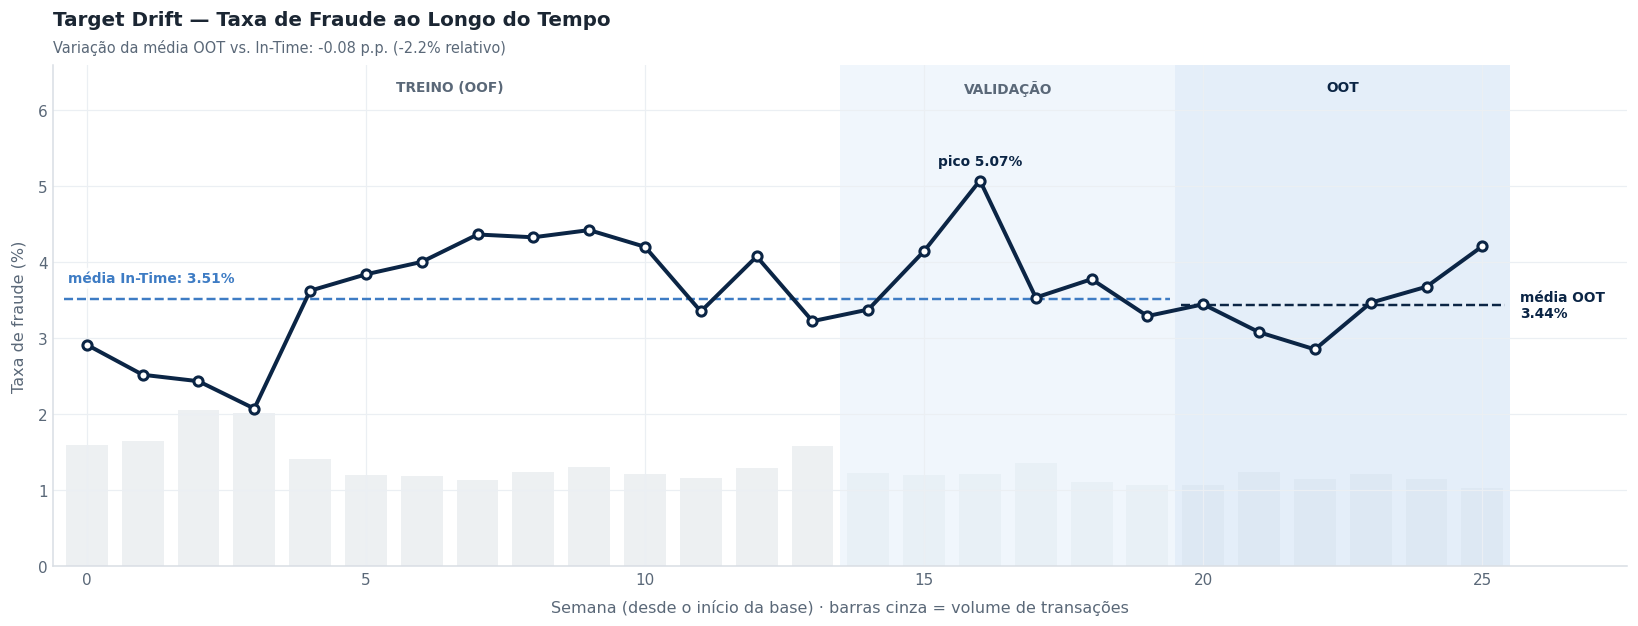

[Qui² — semanas (heterogeneidade temporal)] χ² = 918.16 | gl = 25 | p-valor = 1.29e-177 | V de Cramér = 0.0394 (efeito desprezível)
[Qui² — In-Time x OOT] χ² = 1.45 | gl = 1 | p-valor = 2.28e-01 | V de Cramér = 0.0016 (efeito desprezível)


In [13]:
# ==============================================================================
# 6.1 TARGET DRIFT SEMANAL + TESTE QUI-QUADRADO
# ==============================================================================
df_temporal = tabela_temporal(df_scores, col_bloco='semana', min_fraudes=30, min_transacoes=1000)
medias_taxa = plot_target_drift_temporal(df_temporal, col_bloco='semana', rotulo_bloco='Semana',
                                         filepath=fig_path('09_target_drift_semanal.png'))

# (a) A taxa de fraude varia entre as semanas?
chi2_semanas = teste_qui_quadrado_temporal(df_temporal, rotulo='semanas (heterogeneidade temporal)')
# (b) A taxa de fraude do OOT difere da In-Time?
tab_janelas = df_scores.groupby('Janela').agg(Fraudes=('isFraud', 'sum'), Transacoes=('isFraud', 'size'))
chi2_janelas = teste_qui_quadrado_temporal(tab_janelas, rotulo='In-Time x OOT')

df_temporal.to_csv(DIR_METRICAS / 'avaliacao_metricas_semanais.csv', index=False)

> **Como ler:** p-valor < 0,05 com **V de Cramér < 0,10** = variação estatisticamente detectável, mas de efeito prático desprezível. Picos isolados de fraude costumam ser ataques em rajada (ver arquétipo *Botnet* no `03_Segmentacao`), não mudança estrutural.
>
> **Análise de Resultados — Target Drift** — 📝 _preencher após a execução_

### 6.2 PSI do Score (Estabilidade Populacional Global)

O PSI do **score** é o indicador-síntese de estabilidade: mesmo que features isoladas sofram drift, o que importa para a decisão é se a **distribuição final de risco** mudou. As faixas são os decis do score In-Time (cada uma com 10% da população por construção).

[PSI do Score] PSI = 0.0049 → Estável
[KS shift do score] estatística = 0.0292 (p-valor = 2.79e-70)


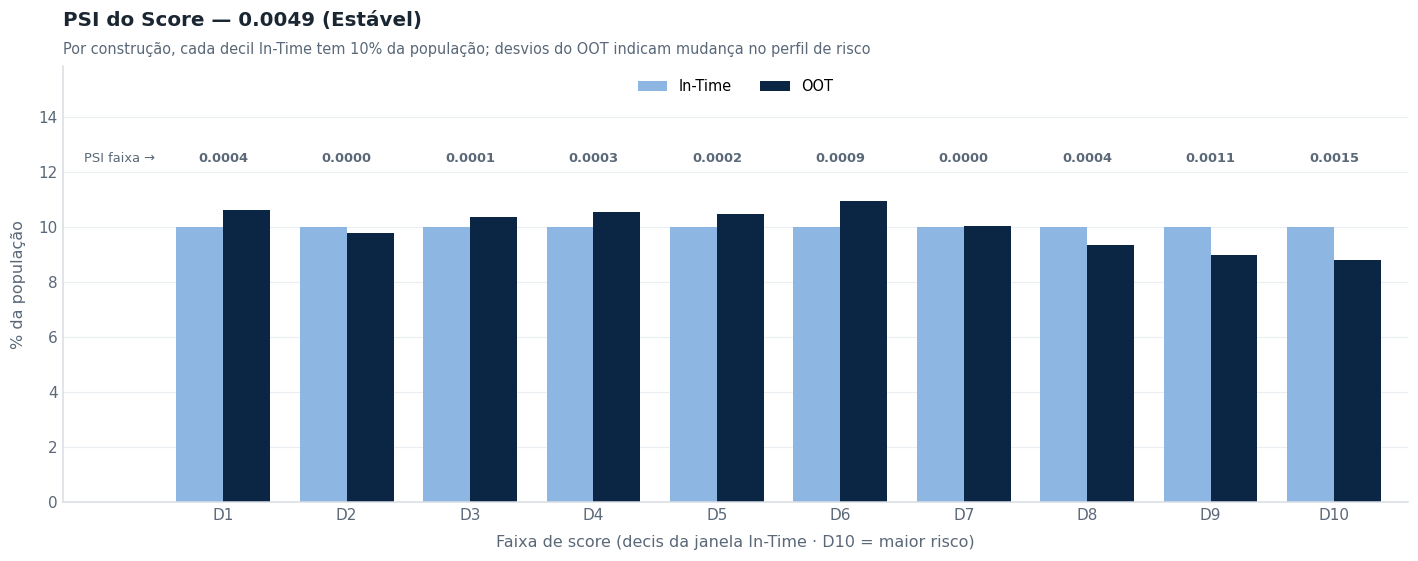

In [14]:
# ==============================================================================
# 6.2 PSI GLOBAL DO SCORE + KS DE DESLOCAMENTO
# ==============================================================================
df_psi_score, psi_score = calcular_psi_scores(base_it['prob_raw'], base_oot['prob_raw'], bins=10)
ks_shift = ks_2samp(base_it['prob_raw'], base_oot['prob_raw'])
print(f"[KS shift do score] estatística = {ks_shift.statistic:.4f} (p-valor = {ks_shift.pvalue:.2e})")

plot_psi_score_faixas(df_psi_score, psi_score, filepath=fig_path('10_psi_score_faixas.png'))

> **Como ler:** barras do OOT acima de 10% nas faixas da direita (D8–D10) = mais transações sendo classificadas como arriscadas, o que aumenta o volume bloqueado. Na esquerda, o oposto.
>
> **Análise de Resultados — PSI do Score** — 📝 _preencher após a execução_

### 6.3 PSI das Features × Importância (SHAP)

Drift só é um problema quando atinge variáveis que **o modelo usa**. Por isso cruzamos o PSI de cada uma das features do modelo com o seu |SHAP| médio (Seção 5.0): o **Risco de Drift** = PSI × % de impacto SHAP prioriza o que monitorar.

In [15]:
# ==============================================================================
# 6.3a PSI DE TODAS AS FEATURES DO MODELO (IN-TIME → OOT)
# ==============================================================================
df_psi_features = relatorio_psi_features(X_in_time, X_oot_m, features=FEATURES, bins=10)
contagem_status = df_psi_features['Status'].value_counts().reindex(['Estável', 'Alerta', 'Crítico'], fill_value=0)
print(f"[PSI features] Estável: {contagem_status['Estável']} | Alerta: {contagem_status['Alerta']} | "
      f"Crítico: {contagem_status['Crítico']} (de {len(df_psi_features)} features do modelo)")

display(df_psi_features.head(15).style.format({
    'PSI': '{:.4f}', 'KS_shift': '{:.4f}', '%_Nulos_InTime': '{:.1f}%', '%_Nulos_OOT': '{:.1f}%',
}).bar(subset=['PSI'], color=PALETA_AZUL['claro'], vmin=0).hide(axis='index'))
df_psi_features.to_csv(DIR_METRICAS / 'avaliacao_psi_features.csv', index=False)

[PSI features] Estável: 42 | Alerta: 2 | Crítico: 0 (de 44 features do modelo)


Feature,PSI,KS_shift,Status,%_Nulos_InTime,%_Nulos_OOT
cont_null_tr,0.2151,0.1407,Alerta,0.0%,0.0%
match_cont_F,0.1272,0.1680,Alerta,0.0%,0.0%
delta_D8,0.0625,0.0638,Estável,87.0%,88.7%
delta_D15,0.0477,0.0901,Estável,16.5%,9.6%
V130,0.0256,0.0721,Estável,0.0%,0.2%
delta_D10,0.0254,0.0619,Estável,14.1%,8.2%
match_assinatura_M1M2M3,0.0244,0.2266,Estável,0.0%,0.0%
delta_D1,0.0240,0.0757,Estável,0.2%,0.3%
id_17,0.0233,0.0761,Estável,75.3%,80.8%
ProductCD,0.0203,0.0731,Estável,0.0%,0.0%


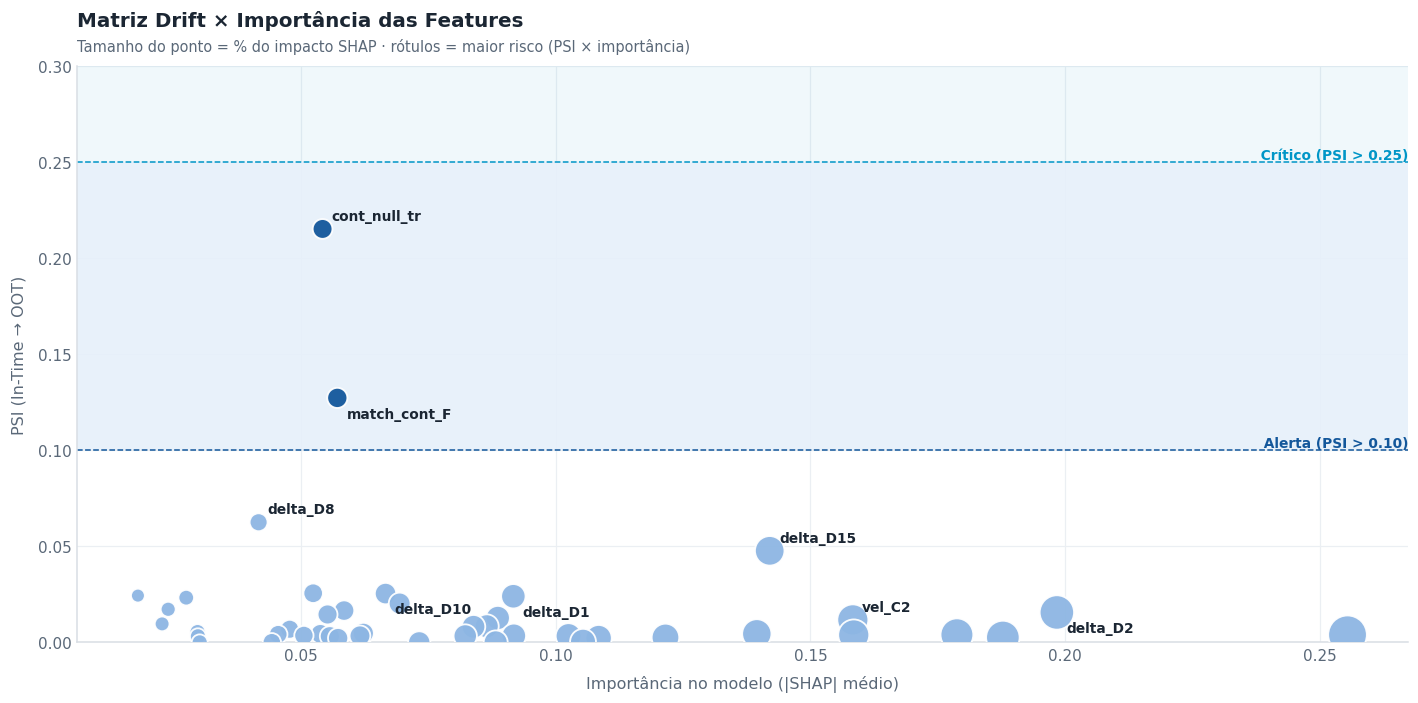

Feature,PSI,Status,Rank SHAP,% Impacto SHAP,Risco_Drift
cont_null_tr,0.2151,Alerta,30,1.48%,0.319
match_cont_F,0.1272,Alerta,27,1.56%,0.199
delta_D15,0.0477,Estável,7,3.88%,0.185
delta_D2,0.0156,Estável,2,5.42%,0.085
delta_D8,0.0625,Estável,37,1.14%,0.071
delta_D1,0.0240,Estável,14,2.51%,0.060
vel_C2,0.0117,Estável,6,4.33%,0.051
delta_D10,0.0254,Estável,22,1.82%,0.046
ProductCD,0.0203,Estável,21,1.90%,0.038
V130,0.0256,Estável,32,1.43%,0.037


In [16]:
# ==============================================================================
# 6.3b MATRIZ DRIFT x IMPORTÂNCIA (PSI x |SHAP|)
# ==============================================================================
df_drift_risco = plot_psi_vs_shap(df_psi_features, rank_shap_oot, n_rotulos=8,
                                  filepath=fig_path('11_matriz_psi_vs_shap.png'))
display(df_drift_risco.head(10)[['Feature', 'PSI', 'Status', 'Rank', '%_Impacto', 'Risco_Drift']]
        .rename(columns={'Rank': 'Rank SHAP', '%_Impacto': '% Impacto SHAP'})
        .style.format({'PSI': '{:.4f}', '% Impacto SHAP': '{:.2f}%', 'Risco_Drift': '{:.3f}'})
        .hide(axis='index'))

[INFO] Features com maior risco de drift (PSI x importância): cont_null_tr, match_cont_F, delta_D15


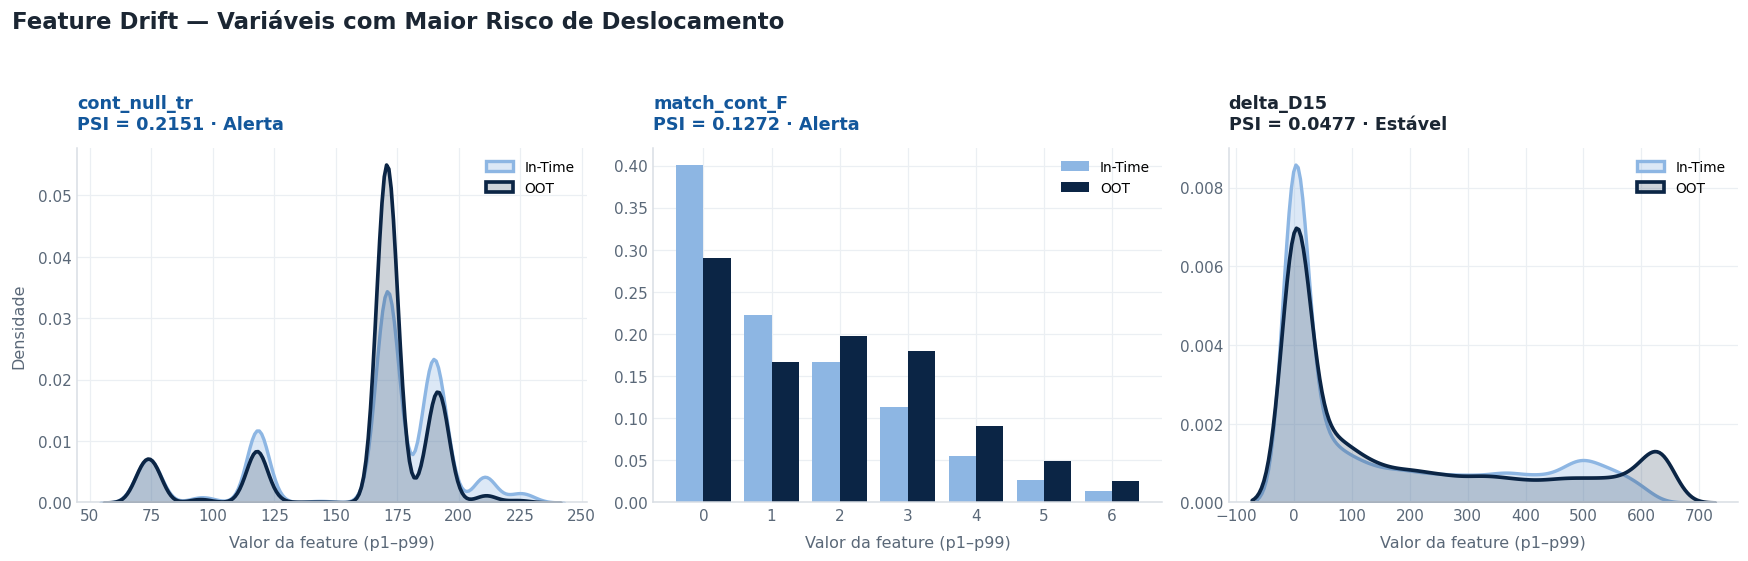

In [17]:
# ==============================================================================
# 6.3c DISTRIBUIÇÕES IN-TIME x OOT DAS 3 FEATURES DE MAIOR RISCO DE DRIFT
# ==============================================================================
top3_drift = df_drift_risco['Feature'].head(3).tolist()
print(f"[INFO] Features com maior risco de drift (PSI x importância): {', '.join(top3_drift)}")
plot_comparativo_psi_features(X_in_time, X_oot_m, top3_drift, bins=10,
                              filepath=fig_path('12_feature_drift_top3.png'))

> **Como ler:** a matriz tem quatro leituras — *(i)* **drift alto + importância alta** (canto superior direito): risco real, prioridade de monitoramento; *(ii)* **drift alto + importância baixa**: ruído com pouco efeito na decisão; *(iii)* **drift baixo + importância alta**: motores estáveis (cenário ideal); *(iv)* demais: irrelevantes. Compare também `%_Nulos_InTime` × `%_Nulos_OOT`: muitos "drifts" em dados de fraude são, na verdade, **mudança na taxa de preenchimento** (ex.: blocos de identidade).
>
> **Análise de Resultados — Feature Drift** — 📝 _preencher após a execução_

---
## 7.0 Estabilidade Temporal do GINI

O GINI agregado do OOT pode esconder semanas ruins. Aqui ele é calculado **semana a semana** ao longo de todo o horizonte — Treino (**OOF**), Validação e OOT — para responder: *a performance degrada progressivamente com o tempo (sinal de concept drift) ou oscila em torno de um patamar estável?*

O piso de aceitação é definido como **90% do GINI médio In-Time** (tolerância de queda relativa de 10%).

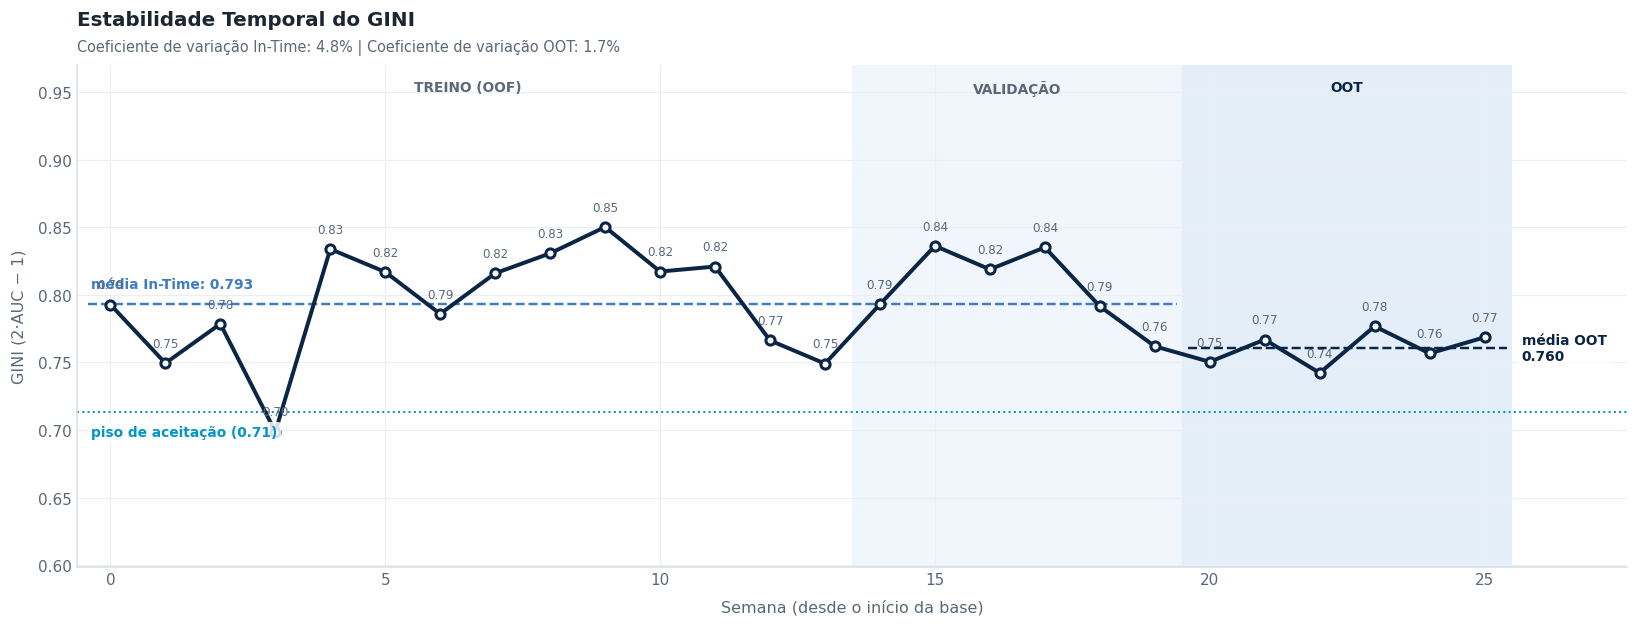

[GINI] Médio In-Time: 0.7929 | Médio OOT: 0.7605 | Piso: 0.7136
[GINI] Semanas OOT abaixo do piso: nenhuma
[GINI] Tendência no OOT: +0.0027 por semana | Correlação taxa de fraude x GINI: +0.66


semana,Particao,Transacoes,Fraudes,Taxa_Fraude_%,GINI,KS,Recall_%,Precision_%,Lucro_USD
0,Treino (OOF),"27,596",804,2.91%,0.7928,0.6443,76.9%,14.6%,"$ 15,799"
1,Treino (OOF),"28,463",717,2.52%,0.7494,0.6169,78.8%,10.1%,"$ 22,513"
2,Treino (OOF),"35,701",869,2.43%,0.7785,0.6327,80.7%,9.2%,"$ 29,316"
3,Treino (OOF),"34,906",724,2.07%,0.6988,0.5534,78.0%,6.1%,"$ 18,439"
4,Treino (OOF),"24,539",889,3.62%,0.8338,0.6845,80.3%,19.8%,"$ 21,946"
5,Treino (OOF),"20,919",803,3.84%,0.8169,0.6533,76.1%,21.0%,"$ 11,064"
6,Treino (OOF),"20,564",823,4.00%,0.7859,0.6088,70.6%,20.4%,"$ 9,769"
7,Treino (OOF),"19,761",862,4.36%,0.8159,0.6560,75.8%,23.2%,"$ 11,537"
8,Treino (OOF),"21,432",927,4.33%,0.8307,0.6832,79.5%,24.6%,"$ 13,045"
9,Treino (OOF),"22,534",996,4.42%,0.8502,0.7104,81.1%,26.5%,"$ 23,656"


In [18]:
# ==============================================================================
# 7.0 GINI SEMANA A SEMANA (TREINO OOF → VALIDAÇÃO → OOT)
# ==============================================================================
TOLERANCIA_QUEDA_GINI = 0.10
d_it = df_temporal[df_temporal['Janela'] == 'In-Time'].dropna(subset=['GINI'])
gini_medio_it = float(np.average(d_it['GINI'], weights=d_it['Transacoes']))
PISO_GINI = gini_medio_it * (1 - TOLERANCIA_QUEDA_GINI)

medias_gini = plot_gini_temporal(df_temporal, col_bloco='semana', rotulo_bloco='Semana', piso_gini=PISO_GINI,
                                 filepath=fig_path('13_gini_temporal_semanal.png'))

d_oot = df_temporal[df_temporal['Janela'] == 'OOT'].dropna(subset=['GINI'])
semanas_abaixo = d_oot.loc[d_oot['GINI'] < PISO_GINI, 'semana'].tolist()
tendencia_oot = np.polyfit(d_oot['semana'], d_oot['GINI'], 1)[0] if len(d_oot) >= 3 else np.nan
corr_taxa_gini = df_temporal[['Taxa_Fraude_%', 'GINI']].corr().iloc[0, 1]

print(f"[GINI] Médio In-Time: {gini_medio_it:.4f} | Médio OOT: {medias_gini.get('OOT', np.nan):.4f} | Piso: {PISO_GINI:.4f}")
print(f"[GINI] Semanas OOT abaixo do piso: {semanas_abaixo if semanas_abaixo else 'nenhuma'}")
print(f"[GINI] Tendência no OOT: {tendencia_oot:+.4f} por semana | Correlação taxa de fraude x GINI: {corr_taxa_gini:+.2f}")

display(df_temporal[['semana', 'Particao', 'Transacoes', 'Fraudes', 'Taxa_Fraude_%', 'GINI', 'KS', 'Recall_%',
                     'Precision_%', 'Lucro_USD']]
        .style.format({'Transacoes': '{:,.0f}', 'Fraudes': '{:,.0f}', 'Taxa_Fraude_%': '{:.2f}%', 'GINI': '{:.4f}',
                       'KS': '{:.4f}', 'Recall_%': '{:.1f}%', 'Precision_%': '{:.1f}%', 'Lucro_USD': '$ {:,.0f}'}, na_rep='—')
        .background_gradient(subset=['GINI'], cmap=utils.CMAP_AZUL)
        .hide(axis='index'))

> **Como ler:** uma **tendência negativa consistente** no OOT é o sinal clássico de *concept drift* (a relação entre features e fraude está mudando) e define a **janela de re-treino**. Oscilações sem tendência, com o coeficiente de variação semelhante ao do In-Time, indicam estabilidade. A correlação taxa de fraude × GINI ajuda a separar efeito de *mix* (semanas com mais ataques fáceis de detectar) de degradação real.
>
> **Análise de Resultados — Estabilidade do GINI** — 📝 _preencher após a execução_

---
## 8.0 Modelo × Clusters de Fraude — Onde o Modelo Falha?

O `03_Segmentacao` agrupou 100% das fraudes em **10 clusters (K-Means no UMAP 10D)**, consolidados em **4 arquétipos de ataque**. Como os clusters existem apenas para fraudes, a pergunta natural é: **qual fração de cada tipo de ataque o modelo barra (Recall) e quanto dinheiro escapa (FN em US$)?**

> **Nota de governança:** os rótulos de cluster são usados aqui **apenas como segmentação descritiva** — não são features do modelo supervisionado, portanto não há vazamento. A função `obter_rotulos_clusters_fraude` reproduz exatamente a esteira do `03` (mesmo recorte, pré-processamento, UMAP e semente) e salva os rótulos em cache (`data/processed/fraude_clusters.parquet`) para as próximas execuções.

### 8.1 Rótulos de Cluster e Arquétipo

In [19]:
# ==============================================================================
# 8.1 RÓTULOS DE CLUSTER (K=10) E ARQUÉTIPOS — MESMO MAPEAMENTO DO 03_SEGMENTACAO
# ==============================================================================
MAPA_CLUSTER_ARQUETIPO = {
    1: '1. Cartão Clonado',
    3: '2. Botnet', 0: '2. Botnet', 4: '2. Botnet', 7: '2. Botnet', 2: '2. Botnet', 6: '2. Botnet',
    9: '3. Roubo de Contas (ATO)', 5: '3. Roubo de Contas (ATO)',
    8: '4. Ataque Inteligente',
}
ORDEM_ARQUETIPOS = [
    '1. Cartão Clonado',
    '2. Botnet',
    '3. Roubo de Contas (ATO)',
    '4. Ataque Inteligente',
]
PALETA_ARQUETIPOS = dict(zip(ORDEM_ARQUETIPOS, [PALETA_AZUL['marinho'], PALETA_AZUL['principal'],
                                                PALETA_AZUL['ciano'], PALETA_AZUL['claro']]))

# Se já houver fraude_clusters.parquet de uma versão anterior do df_master, mude para True na 1ª execução
FORCAR_RECALCULO_CLUSTERS = False

df_clusters = obter_rotulos_clusters_fraude(
    df_master, meta, MAPA_CLUSTER_ARQUETIPO,
    caminho_cache=dir_dados / 'fraude_clusters.parquet',
    k=10, random_state=RANDOM_STATE,
    forcar_recalculo=FORCAR_RECALCULO_CLUSTERS,
)
mapa_id_cluster = df_clusters.set_index('TransactionID')['cluster']

df_fraudes = df_scores[df_scores['isFraud'] == 1].copy()
df_fraudes['cluster'] = df_fraudes['TransactionID'].map(mapa_id_cluster)
df_fraudes['arquetipo'] = df_fraudes['cluster'].map(MAPA_CLUSTER_ARQUETIPO)
df_fraudes['cluster_lbl'] = 'C' + df_fraudes['cluster'].astype('Int64').astype(str)

cobertura = df_fraudes['cluster'].notna().mean()
print(f"Cobertura dos rótulos de cluster nas fraudes escoradas: {cobertura:.2%}")
assert cobertura > 0.99, 'Rótulos de cluster não cobrem as fraudes — verifique o cache/TransactionID.'

# Sanidade (mesma do 03): produto dominante de cada arquétipo vs. assinatura documentada
PRODUTO_ESPERADO = {
    '1. Cartão Clonado': ('W',),
    '2. Botnet': ('C',),
    '3. Roubo de Contas (ATO)': ('R', 'C'),
    '4. Ataque Inteligente': ('H',),
}
produto = df_fraudes['TransactionID'].map(df_master.set_index('TransactionID')['ProductCD'])
dominante = produto.groupby(df_fraudes['arquetipo']).agg(lambda s: s.astype(str).value_counts().idxmax())
divergentes = {
    g: dominante.get(g)
    for g, esp in PRODUTO_ESPERADO.items()
    if dominante.get(g) not in (esp if isinstance(esp, tuple) else (esp,))
}
if divergentes:
    print(f"⚠️ Produto dominante divergente da assinatura documentada: {divergentes} — "
          "se o cache for antigo, rode com FORCAR_RECALCULO_CLUSTERS = True ou revise MAPA_CLUSTER_ARQUETIPO (03_Segmentacao, Seção 6.0).")
else:
    print('✅ Produto dominante de cada arquétipo confere com a assinatura documentada (W / C / R-C / H).')

display(pd.crosstab(df_fraudes['arquetipo'], df_fraudes['Janela'], margins=True, margins_name='Total')
        .reindex(ORDEM_ARQUETIPOS + ['Total']).style.format('{:,.0f}'))

[CLUSTERS] Rótulos carregados do cache: /content/data/processed/fraude_clusters.parquet (20,663 fraudes)
Cobertura dos rótulos de cluster nas fraudes escoradas: 100.00%
⚠️ Produto dominante divergente da assinatura documentada: {'2. Hit and Run': 'C', '3. ATO Premium': 'C'} — os IDs do K-Means dependem do UMAP; revise MAPA_CLUSTER_ARQUETIPO (03_Segmentacao, Seção 6.0).


Janela,In-Time,OOT,Total
arquetipo,,,
1. Botnets,"4,088",910,"4,998"
2. Hit and Run,"3,020",792,"3,812"
3. ATO Premium,967,234,"1,201"
4. Fraude Clássica,"8,524","2,128","10,652"
Total,"16,599","4,064","20,663"


### 8.2 Desempenho do Modelo por Arquétipo de Ataque

Para cada arquétipo e janela: **Recall** (fração das fraudes barradas), prejuízo **evitado** (VP) e **vazado** (FN), e a fatia do vazamento total da janela.

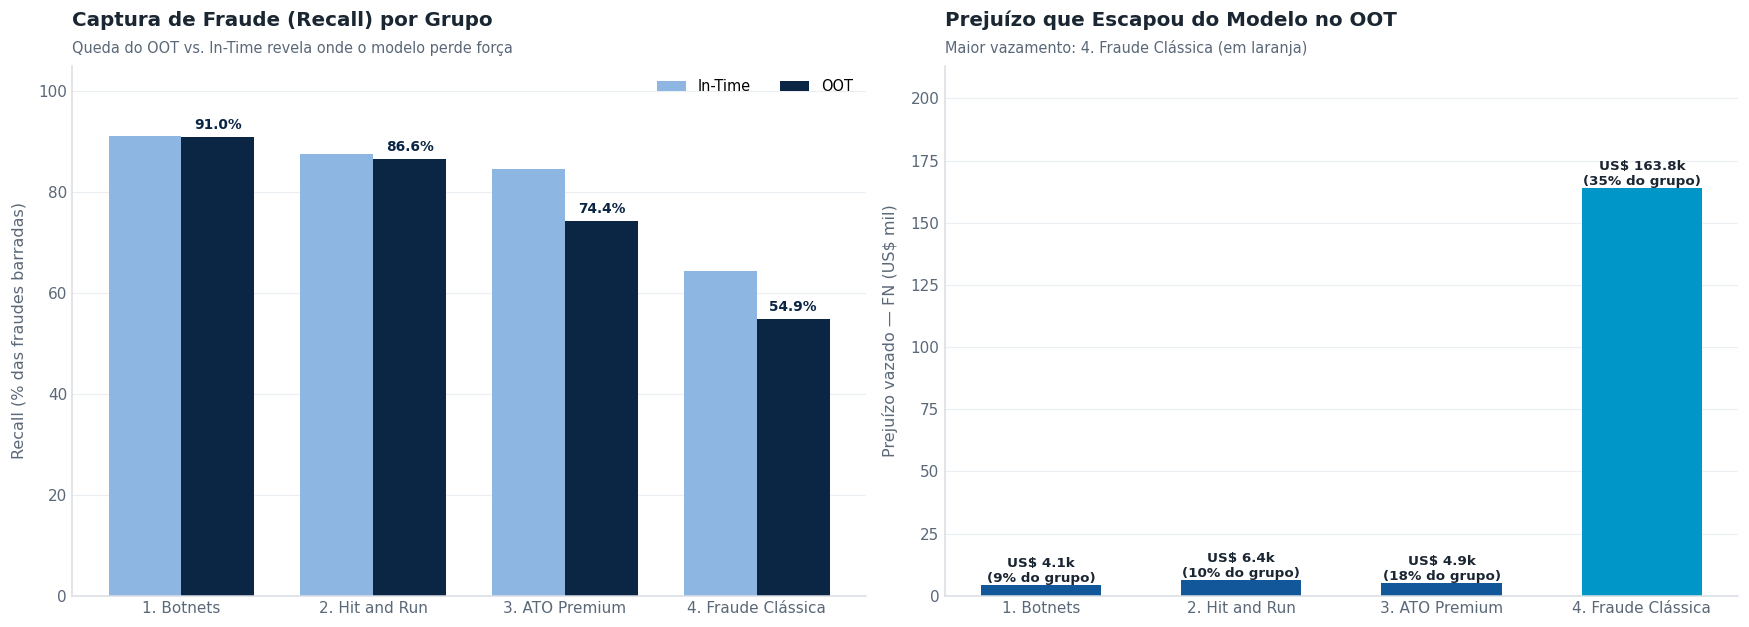

Grupo,Janela,Fraudes,Recall_%,Prejuizo_Total_USD,Prejuizo_Evitado_USD,Prejuizo_Vazado_USD,%_Vazado_USD,Ticket_Medio_USD,Score_Mediano,%_do_Vazamento_da_Janela
1. Botnets,In-Time,"4,088",91.2%,"$ 217,227","$ 199,858","$ 17,369",8.0%,$ 53.14,0.9353,3.1%
1. Botnets,OOT,910,91.0%,"$ 48,555","$ 44,428","$ 4,127",8.5%,$ 53.36,0.9431,2.3%
2. Hit and Run,In-Time,"3,020",87.6%,"$ 293,178","$ 264,579","$ 28,600",9.8%,$ 97.08,0.9412,5.1%
2. Hit and Run,OOT,792,86.6%,"$ 63,275","$ 56,868","$ 6,407",10.1%,$ 79.89,0.9015,3.6%
3. ATO Premium,In-Time,967,84.7%,"$ 98,652","$ 87,543","$ 11,109",11.3%,$ 102.02,0.8916,2.0%
3. ATO Premium,OOT,234,74.4%,"$ 27,320","$ 22,411","$ 4,909",18.0%,$ 116.75,0.8159,2.7%
4. Fraude Clássica,In-Time,"8,524",64.4%,"$ 1,864,853","$ 1,356,011","$ 508,842",27.3%,$ 218.78,0.6019,89.9%
4. Fraude Clássica,OOT,"2,128",54.9%,"$ 470,784","$ 306,960","$ 163,824",34.8%,$ 221.23,0.5024,91.4%


In [20]:
# ==============================================================================
# 8.2a RECALL E PREJUÍZO VAZADO POR ARQUÉTIPO — IN-TIME x OOT
# ==============================================================================
df_arquetipos = avaliar_modelo_por_grupo(df_fraudes, col_grupo='arquetipo', ordem=ORDEM_ARQUETIPOS)
plot_recall_grupos_janelas(df_arquetipos, ordem=ORDEM_ARQUETIPOS, filepath=fig_path('14_recall_vazamento_arquetipos.png'))

display(df_arquetipos.style.format({
    'Fraudes': '{:,.0f}', 'Recall_%': '{:.1f}%', 'Prejuizo_Total_USD': '$ {:,.0f}', 'Prejuizo_Evitado_USD': '$ {:,.0f}',
    'Prejuizo_Vazado_USD': '$ {:,.0f}', '%_Vazado_USD': '{:.1f}%', 'Ticket_Medio_USD': '$ {:,.2f}',
    'Score_Mediano': '{:.4f}', '%_do_Vazamento_da_Janela': '{:.1f}%',
}).hide(axis='index'))
df_arquetipos.to_csv(DIR_METRICAS / 'avaliacao_modelo_por_arquetipo.csv', index=False)

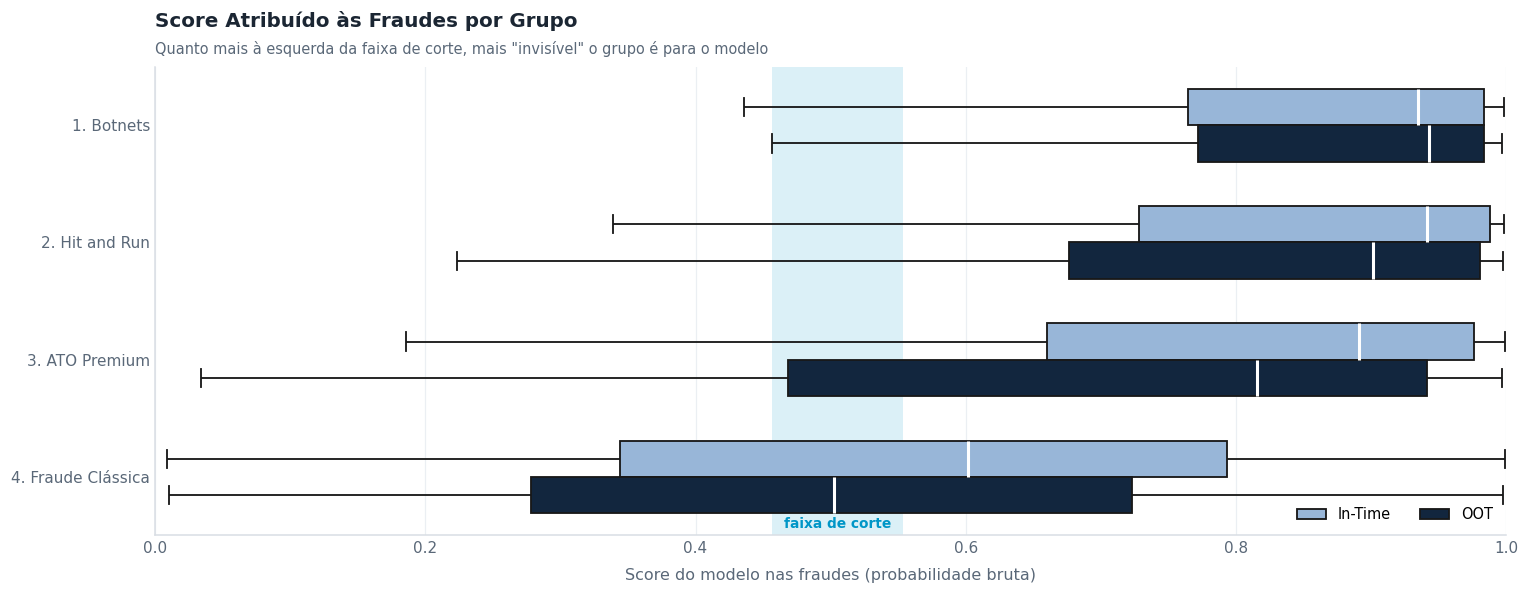

In [21]:
# ==============================================================================
# 8.2b DISTRIBUIÇÃO DO SCORE DAS FRAUDES POR ARQUÉTIPO
# ==============================================================================
plot_score_fraudes_por_grupo(df_fraudes, col_grupo='arquetipo', ordem=ORDEM_ARQUETIPOS,
                             faixa_corte=FAIXA_CORTE_RAW, filepath=fig_path('15_score_fraudes_arquetipos.png'))

> **Como ler:** um arquétipo com **recall alto mas vazamento alto em US$** tem ticket elevado — poucas fraudes que passam custam muito (hipótese do *Cartão Clonado* / *Ataque Inteligente*). Um arquétipo com **score mediano dentro/à esquerda da faixa de corte** é estruturalmente difícil para o modelo (caso típico de ataques sem assinatura extrema ou com comportamento próximo ao legítimo). Esses dois casos pedem estratégias diferentes: regras de ticket/autenticação forte vs. novas features comportamentais.
>
> **Análise de Resultados — Arquétipos** — 📝 _preencher após a execução_

---
## 9.0 Parecer Final — Semáforo Go/No-Go

Os critérios abaixo consolidam todas as seções em uma decisão objetiva. Os limites são parametrizáveis e seguem referências de mercado para modelos de fraude:

| Critério | 🟢 Aprovado | 🟡 Atenção | 🔴 Reprovado |
|---|---|---|---|
| GINI OOT (absoluto) | ≥ 0,60 | 0,50 – 0,60 | < 0,50 |
| Queda relativa do GINI (OOT vs. In-Time) | ≤ 5% | 5% – 10% | > 10% |
| KS OOT | ≥ 0,40 | 0,30 – 0,40 | < 0,30 |
| PSI do score | < 0,10 | 0,10 – 0,25 | ≥ 0,25 |
| Features críticas (PSI ≥ 0,25) no Top 10 SHAP | 0 | 1 | ≥ 2 |
| Erro relativo de calibração no OOT | ≤ 15% | 15% – 30% | > 30% |
| Semanas OOT com GINI abaixo do piso | 0 | 1 | ≥ 2 |
| Lucro OOT vs. sem modelo | Lucro > 0 e > sem modelo | > sem modelo | ≤ sem modelo |

In [22]:
# ==============================================================================
# 9.0 SEMÁFORO GO/NO-GO
# ==============================================================================
def _farol(valor, verde, amarelo, maior_melhor=True):
    if maior_melhor:
        return '🟢 Aprovado' if valor >= verde else ('🟡 Atenção' if valor >= amarelo else '🔴 Reprovado')
    return '🟢 Aprovado' if valor <= verde else ('🟡 Atenção' if valor <= amarelo else '🔴 Reprovado')

queda_gini = 1 - m_oot['GINI'] / m_it['GINI']
top10_shap = set(rank_shap_oot['Feature'].head(10))
n_criticas_top10 = int(df_psi_features[(df_psi_features['Status'] == 'Crítico') & df_psi_features['Feature'].isin(top10_shap)].shape[0])
erro_calib_oot = abs(base_oot['prob_cal'].mean() / base_oot['isFraud'].mean() - 1)
lucro_oot, lucro_sem = m_oot['Lucro Líquido'], m_oot['Lucro Sem Modelo']

semaforo = pd.DataFrame([
    {'Critério': 'GINI OOT', 'Valor': f"{m_oot['GINI']:.4f}", 'Status': _farol(m_oot['GINI'], 0.60, 0.50)},
    {'Critério': 'Queda relativa do GINI', 'Valor': f"{queda_gini:+.1%}", 'Status': _farol(queda_gini, 0.05, 0.10, False)},
    {'Critério': 'KS OOT', 'Valor': f"{m_oot['KS']:.4f}", 'Status': _farol(m_oot['KS'], 0.40, 0.30)},
    {'Critério': 'PSI do score', 'Valor': f"{psi_score:.4f}", 'Status': _farol(psi_score, 0.0999, 0.2499, False)},
    {'Critério': 'Features críticas no Top 10 SHAP', 'Valor': f"{n_criticas_top10}", 'Status': _farol(n_criticas_top10, 0, 1, False)},
    {'Critério': 'Erro de calibração OOT', 'Valor': f"{erro_calib_oot:.1%}", 'Status': _farol(erro_calib_oot, 0.15, 0.30, False)},
    {'Critério': 'Semanas OOT abaixo do piso de GINI', 'Valor': f"{len(semanas_abaixo)}", 'Status': _farol(len(semanas_abaixo), 0, 1, False)},
    {'Critério': 'Lucro OOT vs. sem modelo', 'Valor': f"$ {lucro_oot:,.0f} vs. $ {lucro_sem:,.0f}",
     'Status': '🟢 Aprovado' if (lucro_oot > 0 and lucro_oot > lucro_sem) else ('🟡 Atenção' if lucro_oot > lucro_sem else '🔴 Reprovado')},
])
n_red, n_yel = semaforo['Status'].str.contains('🔴').sum(), semaforo['Status'].str.contains('🟡').sum()
PARECER = 'NO-GO' if n_red > 0 else ('GO COM RESSALVAS' if n_yel > 0 else 'GO')

display(semaforo.style.hide(axis='index').set_properties(**{'text-align': 'left'}))
print('=' * 70)
print(f" PARECER: {PARECER}  ({n_red} reprovado(s) · {n_yel} atenção · {len(semaforo) - n_red - n_yel} aprovado(s))")
print('=' * 70)

Critério,Valor,Status
GINI OOT,0.7607,🟢 Aprovado
Queda relativa do GINI,+3.8%,🟢 Aprovado
KS OOT,0.5960,🟢 Aprovado
PSI do score,0.0049,🟢 Aprovado
Features críticas no Top 10 SHAP,0,🟢 Aprovado
Erro de calibração OOT,14.4%,🟢 Aprovado
Semanas OOT abaixo do piso de GINI,0,🟢 Aprovado
Lucro OOT vs. sem modelo,"$ 34,512 vs. $ -297,264",🟢 Aprovado


 PARECER: GO  (0 reprovado(s) · 0 atenção · 8 aprovado(s))


### 9.1 Exportação das Métricas de Monitoramento (MLOps)

Persistência em `artifacts/monitoramento_oot.json` de tudo o que alimenta o monitoramento contínuo em produção: discriminação, regra de decisão, financeiro, drift (score e features), estabilidade semanal, desempenho por arquétipo e o parecer.

In [23]:
# ==============================================================================
# 9.1 EXPORTAÇÃO DAS MÉTRICAS DE MONITORAMENTO CONTÍNUO
# ==============================================================================
from scipy.stats import spearmanr


def _limpo(obj):
    # Converte tipos numpy/pandas em tipos nativos JSON
    return json.loads(pd.Series([obj]).to_json(orient='records', force_ascii=False))[0]

# Estabilidade dos motores de decisão: Spearman entre os rankings de |SHAP| In-Time x OOT
_shap_m = rank_shap_oot[['Feature', 'SHAP_medio_abs']].merge(
    rank_shap_it[['Feature', 'SHAP_medio_abs']], on='Feature', suffixes=('_OOT', '_InTime'))
spearman_shap = float(spearmanr(_shap_m['SHAP_medio_abs_InTime'], _shap_m['SHAP_medio_abs_OOT']).correlation)

# Arquétipo que mais vaza prejuízo (US$) no OOT
_arq_oot = df_arquetipos[df_arquetipos['Janela'] == 'OOT']
pior_arquetipo = _arq_oot.loc[_arq_oot['Prejuizo_Vazado_USD'].idxmax()]

monitoramento = {
    'timestamp_avaliacao': datetime.now().isoformat(timespec='seconds'),
    'modelo': artefato['nome_modelo'],
    'hash_artefato': hash_artefato,
    'total_features': len(FEATURES),
    'regra_decisao': REGRA,
    'treino_escorado_oof': bool(USAR_OOF_TREINO),
    'metricas_por_base': {b: df_metricas[b].to_dict() for b in bases_avaliacao},
    'delta_oot_vs_in_time': df_metricas['Δ (OOT − In-Time)'].dropna().to_dict(),
    'separacao': {'ks_in_time': ks_it, 'ks_oot': ks_oot, 'monotonico_oot': monotonico_oot,
                  'lift_decil10_oot': float(top['lift']), 'captura_decil10_oot_pct': float(top['captura_fraudes_acum_pct'])},
    'drift': {
        'taxa_fraude_media': medias_taxa,
        'qui2_in_time_vs_oot': chi2_janelas,
        'psi_score': psi_score, 'status_psi_score': 'Estável' if psi_score < 0.10 else ('Alerta' if psi_score < 0.25 else 'Crítico'),
        'ks_shift_score': float(ks_shift.statistic),
        'psi_features': df_psi_features.set_index('Feature')['PSI'].to_dict(),
        'top_risco_drift': df_drift_risco.head(10)[['Feature', 'PSI', 'Risco_Drift']].to_dict(orient='records'),
    },
    'shap': {'spearman_in_time_vs_oot': spearman_shap,
             'top15_oot': rank_shap_oot.head(15)[['Feature', 'SHAP_medio_abs']].to_dict(orient='records')},
    'estabilidade_temporal': {'gini_medio': medias_gini, 'piso_gini': PISO_GINI, 'semanas_oot_abaixo_piso': semanas_abaixo,
                              'tendencia_gini_oot_semana': tendencia_oot,
                              'serie_semanal': df_temporal[['semana', 'Particao', 'Taxa_Fraude_%', 'GINI', 'Recall_%']].to_dict(orient='records')},
    'arquetipos': {'por_arquetipo': df_arquetipos.astype({'Grupo': str}).to_dict(orient='records'),
                 'pior_arquetipo_oot': str(pior_arquetipo['Grupo']),
                 'pior_arquetipo_oot_vazamento_usd': float(pior_arquetipo['Prejuizo_Vazado_USD'])},
    'parecer': {'decisao': PARECER, 'semaforo': semaforo.to_dict(orient='records')},
}

caminho_monitoramento = dir_artifacts / 'monitoramento_oot.json'
with open(caminho_monitoramento, 'w', encoding='utf-8') as f:
    json.dump(_limpo(monitoramento), f, indent=2, ensure_ascii=False)

print(f"[MLOps] Métricas de monitoramento exportadas: {caminho_monitoramento.relative_to(PROJECT_ROOT)}")
print(f"[MLOps] CSVs em: {DIR_METRICAS.relative_to(PROJECT_ROOT)} "
      f"({', '.join(sorted(p.name for p in DIR_METRICAS.glob('avaliacao_*.csv')))})")

[MLOps] Métricas de monitoramento exportadas: artifacts/monitoramento_oot.json
[MLOps] CSVs em: reports/metrics (avaliacao_metricas_in_time_vs_oot.csv, avaliacao_metricas_semanais.csv, avaliacao_modelo_por_arquetipo.csv, avaliacao_psi_features.csv)


---
## 10.0 Conclusões

> 📝 _Preencher após a execução, seguindo o roteiro do storytelling:_

### Resumo Executivo — In-Time vs. OOT

| Métrica | In-Time | OOT | Δ | Diagnóstico |
|:---|:---:|:---:|:---:|:---|
| **GINI** | | | | |
| **ROC-AUC** | | | | |
| **KS** | | | | |
| **PR-AUC** | | | | |
| **Recall (regra dinâmica)** | | | | |
| **Precision (regra dinâmica)** | | | | |
| **Lucro por Transação** | | | | |

### Principais Achados
* **Performance (Seções 2–4):** …
* **Interpretabilidade (Seção 5):** …
* **Drift (Seção 6):** …
* **Estabilidade temporal (Seção 7):** …
* **Pontos cegos por arquétipo (Seção 8):** …

### Pontos Fortes vs. Pontos de Atenção
* **Fortes:** …
* **Atenção:** …

### Recomendações e Próximos Passos
1. **Monitoramento:** PSI semanal do score e das features de maior *Risco de Drift* (Seção 6.3).
2. **Re-treino:** gatilho quando o GINI semanal ficar abaixo do piso por 2 semanas seguidas (Seção 7.0).
3. **Pontos cegos:** estratégia dedicada para o arquétipo/cluster de maior prejuízo vazado (Seção 8.3–8.4).